# Lab01 - sprint 1

**Исследование физико-химических измерений белых вин (Wine Quality, Vinho Verde)**

Команда № 27 (лист lab01_groups журнала): Нефедьева Антонина Сергеевна (ИСУ 502335, поток 96161, трек «Инфохимия») и Быкова Кристина Денисовна (ИСУ 501322, трек КТвД).

| | |
|---|---|
| Датасет | Wine Quality, Cortez et al. (2009), UCI ML Repository, белые вина N = 4898, красные N = 1599 |
| Генеральная совокупность | все 4898 образцов белого вина из датасета |
| Случайные величины | RV01 **pH**, RV02 **фиксированная кислотность**, RV03 **содержание спирта** |
| Код | личный пакет `labstat/` (подключается ниже), автотесты в `tests/` |
| КТвД | Быкова Кристина Денисовна (ИСУ 501322, группа 27): оформление, доп. задание, датчик на marimo, сайт |
| Тексты выводов спринта 1 | Быкова Кристина Денисовна: природа событий, обоснование распределений и выводы (разделы 2.1, 2.2.1, 2.7, 3.1, 3.2.1, 3.7, 4.1, 4.2.1, 4.7, 5.3) |

**Как запустить.** `pip install -r requirements.txt`, затем выполнить ноутбук сверху вниз из корня репозитория. Данные лежат в `data/`, контрольная сумма проверяется при загрузке. В Colab сначала выполнить в первой ячейке `!git clone https://github.com/kkristinabbykova/lab01-statistics.git` и `%cd lab01-statistics`, иначе пакет `labstat` не найдётся.

<a id="toc"></a>
**Содержание**

- [1. Dataset: Wine Quality (белые вина)](#dataset)
- [2. Random Variable 01 (pH)](#rv01)
    - [2.1 Description (природа события)](#rv01-desc)
    - [2.2 EDA & Distribution](#rv01-eda)
        - [2.2.1 Математическое описание распределения](#rv01-math)
    - [2.3 Independence & Estimations](#rv01-indep)
        - [2.3.1 Зависимость](#rv01-dep)
        - [2.3.2 Состоятельность оценок](#rv01-cons)
    - [2.4 Normalization](#rv01-norm)
    - [2.5 Sample vs Population](#rv01-sample)
    - [2.6 Hypotheses](#rv01-hyp)
    - [2.7 Resume](#rv01-resume)
- [3. Random Variable 02 (фиксированная кислотность)](#rv02)
    - [3.1 Description (природа события)](#rv02-desc)
    - [3.2 EDA & Distribution](#rv02-eda)
        - [3.2.1 Математическое описание распределения](#rv02-math)
    - [3.3 Independence & Estimations](#rv02-indep)
        - [3.3.1 Зависимость](#rv02-dep)
        - [3.3.2 Состоятельность оценок](#rv02-cons)
    - [3.4 Normalization](#rv02-norm)
    - [3.5 Sample vs Population](#rv02-sample)
    - [3.6 Hypotheses](#rv02-hyp)
    - [3.7 Resume](#rv02-resume)
- [4. Random Variable 03 (спирт)](#rv03)
    - [4.1 Description (природа события)](#rv03-desc)
    - [4.2 EDA & Distribution](#rv03-eda)
        - [4.2.1 Математическое описание распределения](#rv03-math)
    - [4.3 Independence & Estimations](#rv03-indep)
        - [4.3.1 Зависимость](#rv03-dep)
        - [4.3.2 Состоятельность оценок](#rv03-cons)
    - [4.4 Normalization](#rv03-norm)
    - [4.5 Sample vs Population](#rv03-sample)
    - [4.6 Hypotheses](#rv03-hyp)
    - [4.7 Resume](#rv03-resume)
- [5. Lab resume](#resume)
    - [5.1 Итоговые метрики](#resume-metrics)
    - [5.2 Все проверенные гипотезы и поправка Холма](#resume-hyp)
    - [5.3 Выводы по датасету](#resume-conclusions)
    - [5.4 Литература и материалы](#resume-lit)
    - [5.5 cat_mark_table](#resume-marks)




**Lab01 - sprint 2**

- [6. random 01 (датчик pH)](#sp2)
    - [6.1 Description](#sp2-desc)
    - [6.2 math desc](#sp2-math)
    - [6.3 code](#sp2-code)
    - [6.4 tests](#sp2-tests)
    - [6.5 resume](#sp2-resume)
- [7. Исследование алгоритмов датчиков](#sp2-algo)
    - [7.1 Сводная таблица](#sp2-algo-table)
    - [7.2 Методы превращения](#sp2-algo-methods)
    - [7.3 Базовые датчики](#sp2-algo-bases)
    - [7.4 Пример: шесть методов на pH](#sp2-algo-ph)
    - [7.5 Пример: тройки чисел](#sp2-algo-triples)
- [8. Lab resume](#sp2-lab)
    - [8.1 Итоговые метрики датчика](#sp2-metrics)
    - [8.2 Литература спринта 2](#sp2-lit)
    - [8.3 cat_mark_table](#sp2-marks)

**Часть КТвД.** Оформление этого ноутбука сделано здесь. Доп. задание КТвД (датасет шрифтов, интерактивный датчик на marimo, сайт) лежит в отдельном репозитории (Быкова К. Д.).

*Код в ячейках скрыт, чтобы документ читался как отчёт: раскрыть — щелчок по полоске слева от ячейки (JupyterLab) или по «…». Все рисунки пронумерованы, подпись под каждым.*

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from labstat import data, describe as dsc, stochastic, dependence, estimation, sampling, normalize, distributions as dist, hypotheses as hyp
from labstat import plots

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 4)
plots.style()
SEED = 2026

white = data.load_wine("white")   # генеральная совокупность
red = data.load_wine("red")       # дополнительный набор для сравнения
X = white.drop(columns="quality") # 11 физико-химических измерений
white.shape, red.shape

((4898, 12), (1599, 12))

<a id="dataset"></a>
## 1. Dataset: Wine Quality (белые вина)

Португальские вина Vinho Verde, 2004–2007 гг. Для каждого образца лаборатория сертификации измерила 11 физико-химических показателей, а эксперты поставили оценку качества (медиана не менее трёх оценок, шкала 0–10). Источник: Cortez P. et al., 2009 [1]. Единицы измерения по описанию датасета: кислоты, сахар, хлориды, сульфаты в г/дм³, диоксид серы в мг/дм³, плотность в г/см³, спирт в % об.

Почему этот датасет подходит направлению «Инфохимия»: это результаты аналитической химии (титрование, pH-метрия, денсиметрия), из которых потом строят модели.

<sub>[↑ к содержанию](#toc)</sub>

In [2]:
units = pd.Series(data.UNITS, name="единицы")
overview = pd.DataFrame({
    "единицы": units,
    "пропуски": white.isna().sum(),
    "уникальных": white.nunique(),
    "min": white.min(), "max": white.max(),
})
overview

,единицы,пропуски,уникальных,min,max
fixed_acidity,г/дм³ (винная к-та),0,68,3.8000,14.200
volatile_acidity,г/дм³ (уксусная к-та),0,125,0.0800,1.100
citric_acid,г/дм³,0,87,0.0000,1.660
residual_sugar,г/дм³,0,310,0.6000,65.800
chlorides,г/дм³ (NaCl),0,160,0.0090,0.346
free_so2,мг/дм³,0,132,2.0000,289.000
total_so2,мг/дм³,0,251,9.0000,440.000
density,г/см³,0,890,0.9871,1.039
ph,ед. pH,0,103,2.7200,3.820
sulphates,г/дм³ (K₂SO₄),0,79,0.2200,1.080


In [3]:
print("Полных дубликатов строк:", white.duplicated().sum(), "из", len(white))
odd_alc = white.alcohol[(np.round(white.alcohol * 10) - white.alcohol * 10).abs() > 1e-6]
print("Значений спирта не кратных 0.1 % об.:", odd_alc.size, "примеры:", np.round(odd_alc.unique()[:5], 4))
print("Оценки качества:", white.quality.value_counts().sort_index().to_dict())
order = pd.DataFrame({c: stochastic.runs_test(white[c]) | {"acf_lag1": stochastic.lag_autocorr(white[c])}
                      for c in ["ph", "fixed_acidity", "alcohol"]}).T
order[["runs", "expected", "z", "p", "acf_lag1"]]

Полных дубликатов строк: 937 из 4898
Значений спирта не кратных 0.1 % об.: 69 примеры: [11.94   12.8933 11.4667 10.98   10.0333]
Оценки качества: {3: 20, 4: 163, 5: 1457, 6: 2198, 7: 880, 8: 175, 9: 5}


,runs,expected,z,p,acf_lag1
ph,1974.0,2380.2588,-11.7818,4.8469e-32,0.1870
fixed_acidity,1744.0,2295.5538,-16.2871,1.2191e-59,0.2748
alcohol,1846.0,2372.5490,-15.2957,8.1622e-53,0.2475


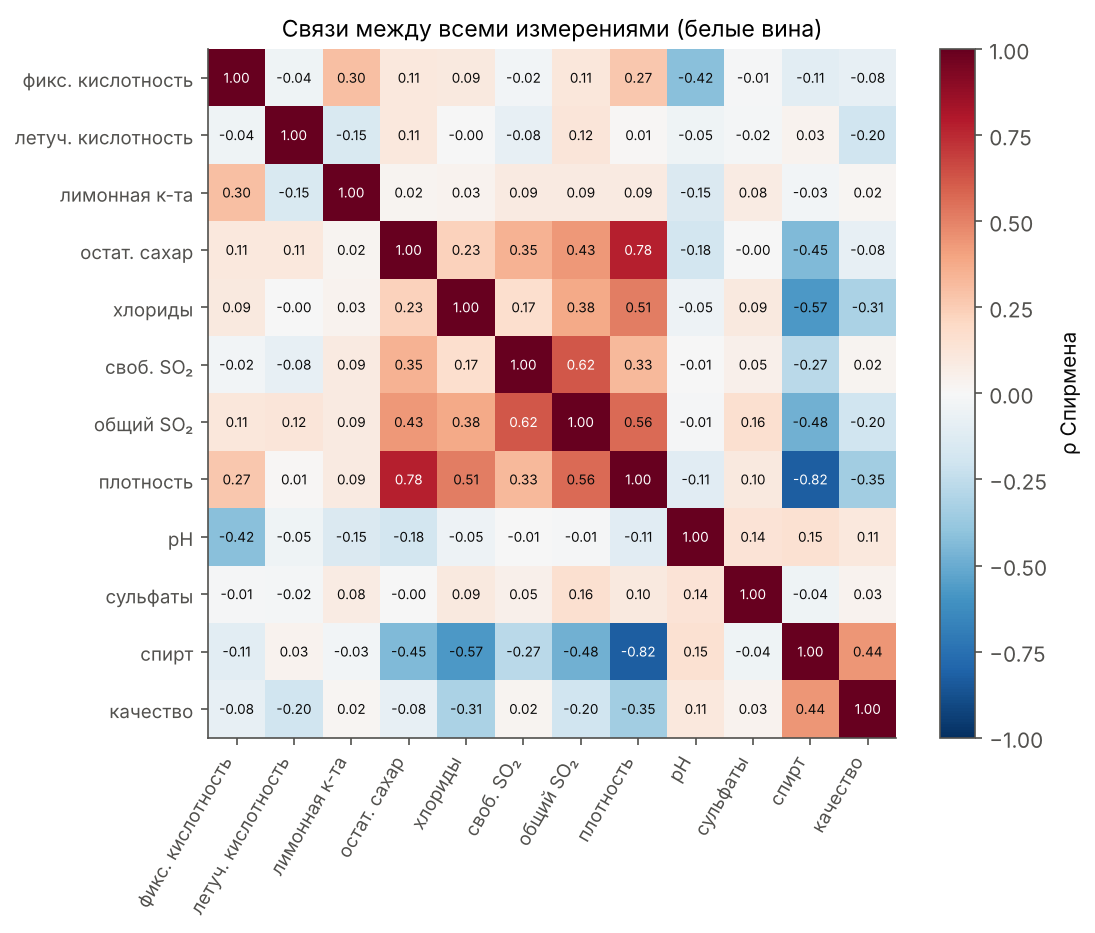

In [4]:
plots.corr_heatmap(white.corr(method="spearman"), "dataset_corr.png");

<a id="fig1"></a>
*Рис. 1. Ранговые корреляции Спирмена $\rho$ между всеми измерениями белых вин.*

**Результаты:**

- Пропусков нет. Полных дублей строк 937 из 4898 (19 %). Совокупность взята как есть; в EDA каждой величины есть столбец «без дублей» для сравнения (средние отличаются меньше чем на 0.08).
- Шаг записи: pH 0.01; кислотность 0.1 (5 значений с шагом 0.05); спирт 0.1, кроме 69 значений вида 11.9333 или 12.8933.
- Критерий серий по порядку строк: $z$ от $-11.8$ до $-16.3$ ($p < 10^{-30}$), автокорреляция соседних строк 0.19–0.27. $H_0$ «порядок строк случаен» отвергается. Все выборки в работе берутся случайным отбором.
- Карта $\rho$ Спирмена: наибольшие по модулю связи: плотность и спирт −0.82, плотность и остаточный сахар +0.78. У pH наибольшая по модулю связь с фиксированной кислотностью (−0.42).

<a id="rv01"></a>
## 2. Random Variable 01 (pH)

<sub>[↑ к содержанию](#toc)</sub>

<a id="rv01-desc"></a>
### 2.1 Description (природа события)

**Величина.** $\mathrm{pH} = -\lg a(\mathrm{H}^+)$, ед. pH, измерение pH-метром, записано с шагом 0.01.

**Событие.** Из совокупности 4898 белых вин случайно выбирается один образец, у него измерен pH.

**Что посчитано для проверки стохастической природы.** Прогноз pH по остальным 10 измерениям двумя способами на 5-кратной кросс-валидации: линейная регрессия и нелинейный прогноз по $k$ ближайшим соседям. Для каждого: $R^2$ и СКО остатка, их сравнение с шагом записи. Плюс поиск вин с полностью совпадающими остальными измерениями и разным pH.

**Природа события.** pH вина в реальной жизни зависит от других компонентов вина: кислот и солей, сорта винограда, погоды в год сбора, способа приготовления и другого. Мы не можем узнать pH случайно выбранного вина заранее, так как эта величина зависит от множества факторов и у каждого вина она разная. Угадать её по другим измерениям можно, но неточно: по 10 измерениям датасета прогноз объясняет только половину разброса ($R^2 = 0.50$), а ошибка прогноза (0.107) в 10 раз больше шага прибора 0.01. Дело в том, что в нашем датасете есть только определённые значения состава вина, а не все: например, основные нелетучие кислоты (винная, яблочная) записаны одним числом, а калия, который гасит кислотность, нет совсем. Поэтому расчёт не доказывает, что pH нельзя вычислить в принципе. Он показывает, что по нашим данным его вычислить нельзя, и для нас pH ведёт себя как случайная величина.

<sub>[↑ к содержанию](#toc)</sub>

Линейная модель: R² на кросс-валидации 0.501, СКО остатка 0.1067 ед. pH
k ближайших соседей, k = 5: R² 0.485, СКО остатка 0.1083 ед. pH
k ближайших соседей, k = 15: R² 0.435, СКО остатка 0.1135 ед. pH
k ближайших соседей, k = 30: R² 0.390, СКО остатка 0.1179 ед. pH
Шаг записи прибора: 0.01 ед. pH; СКО самой величины: 0.1510
Групп вин с одинаковыми остальными 10 измерениями, но разным значением: 0


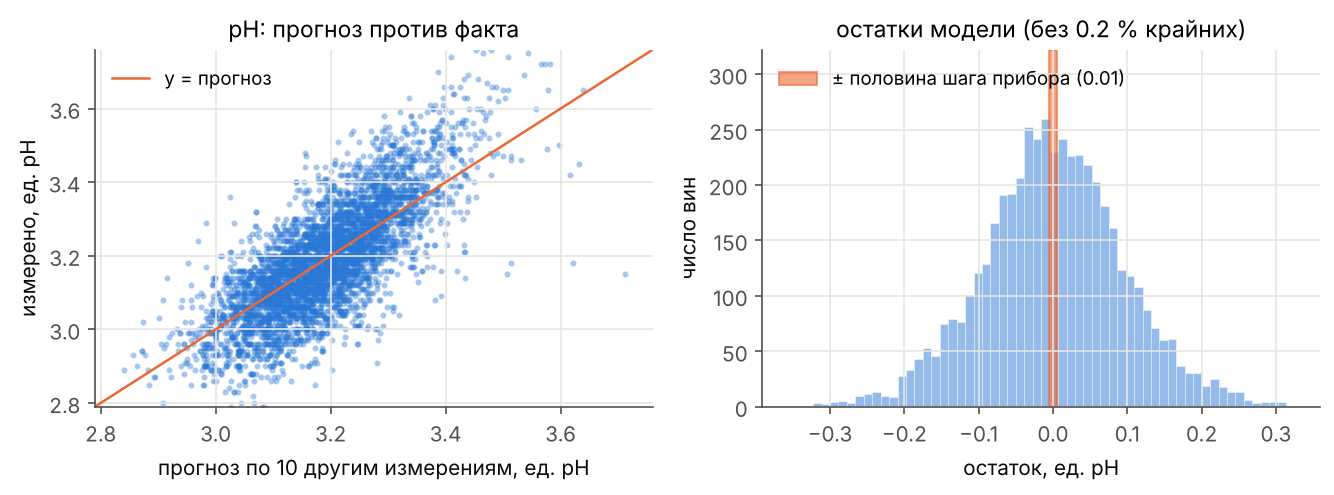

,nunique,min,max,count


In [5]:
res_rv01 = stochastic.cv_r2_linear(X.drop(columns="ph"), X["ph"], k=5, seed=SEED)
knn_rv01 = {kk: stochastic.cv_r2_knn(X.drop(columns="ph"), X["ph"], k_neighbors=kk, k=5, seed=SEED) for kk in (5, 15, 30)}
twins_rv01 = stochastic.same_inputs_different_target(X, "ph")
print(f"Линейная модель: R² на кросс-валидации {res_rv01['r2_cv']:.3f}, СКО остатка {res_rv01['resid_std']:.4f} ед. pH")
for kk, r in knn_rv01.items():
    print(f"k ближайших соседей, k = {kk}: R² {r['r2_cv']:.3f}, СКО остатка {r['resid_std']:.4f} ед. pH")
print(f"Шаг записи прибора: 0.01 ед. pH; СКО самой величины: {X['ph'].std():.4f}")
print(f"Групп вин с одинаковыми остальными 10 измерениями, но разным значением: {len(twins_rv01)}")
plots.stochastic_panel(X["ph"].to_numpy(), res_rv01["resid"], "pH", "ед. pH", 0.01, "rv01_stochastic.png");
twins_rv01.head()

<a id="fig2"></a>
*Рис. 2. pH: прогноз по 10 другим измерениям против измеренного значения (слева) и остатки модели в сравнении с шагом записи прибора (справа).*

**Результаты:**

- Линейная модель по 10 другим измерениям: $R^2$ на кросс-валидации 0.50, СКО остатка 0.107 ед. pH.
- $k$ ближайших соседей (нелинейный прогноз): $R^2$ 0.49 / 0.44 / 0.39 при $k = 5 / 15 / 30$, СКО остатка 0.108–0.118.
- Шаг записи 0.01, СКО самого pH 0.151.
- Групп вин с одинаковыми остальными измерениями и разным pH: 0.

<a id="rv01-eda"></a>
### 2.2 EDA & Distribution

<sub>[↑ к содержанию](#toc)</sub>

In [6]:
x_rv01 = white["ph"].to_numpy()
out_rv01 = dsc.iqr_outliers(x_rv01)
print("Выбросов по правилу 1.5·IQR:", out_rv01.sum(), f"({out_rv01.mean():.1%})")
dsc.compare_table({"белые, все": x_rv01, "белые без дублей": white.drop_duplicates()["ph"], "красные": red["ph"]}).T

Выбросов по правилу 1.5·IQR: 75 (1.5%)


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
"белые, все",4898.0,3.1883,0.0228,0.1510,0.0474,2.72,3.09,3.18,3.28,3.82,0.19,3.14,0.4576,0.5290,103.0,0.01
белые без дублей,3961.0,3.1955,0.0230,0.1515,0.0474,2.72,3.09,3.18,3.29,3.82,0.20,3.16,0.4553,0.5477,103.0,0.01
красные,1599.0,3.3111,0.0238,0.1544,0.0466,2.74,3.21,3.31,3.40,4.01,0.19,3.30,0.1935,0.8007,89.0,0.01


In [7]:
fit_rv01 = dist.fit_candidates(x_rv01)
fit_rv01

,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
skewnorm,3,2385.7600,-4765.5200,-4746.0303,0.0245,"(1.8161, 3.0412, 0.2107)"
lognorm,3,2385.7365,-4765.4731,-4745.9833,0.0246,"(0.1363, 2.0877, 1.0904)"
gamma,3,2383.8781,-4761.7563,-4742.2665,0.0250,"(26.1137, 2.4184, 0.0295)"
norm,2,2310.0684,-4616.1368,-4603.1436,0.0493,"(3.1883, 0.151)"
weibull_min,3,2250.7030,-4495.4060,-4475.9162,0.0593,"(3.0322, 2.7183, 0.5243)"


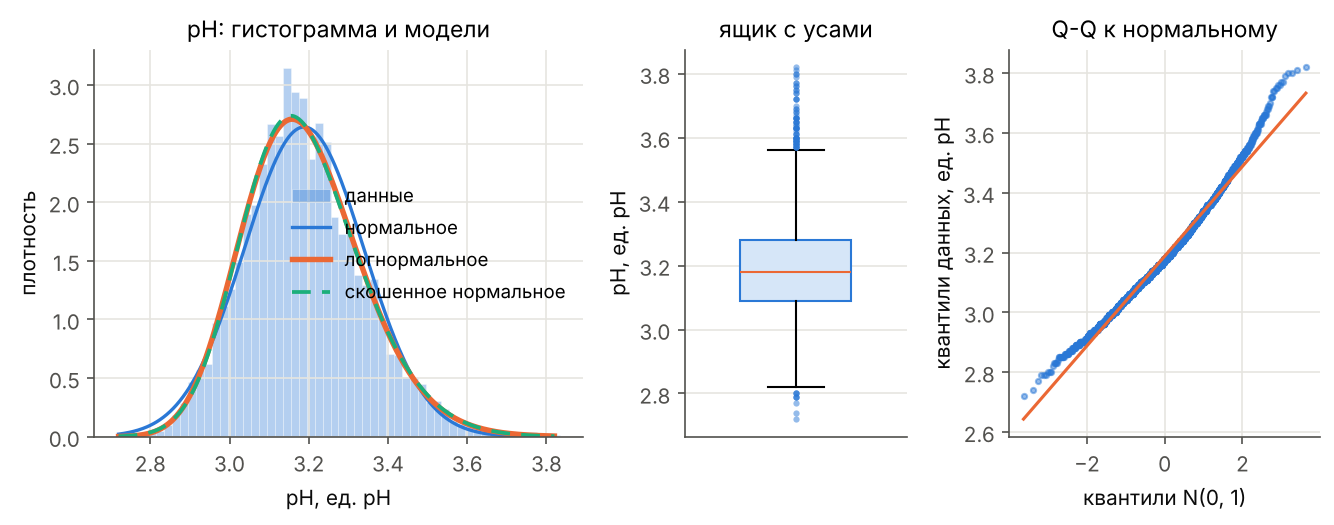

In [8]:
best_rv01 = {name: dist.fit(name, x_rv01) for name in ['norm', 'lognorm', 'skewnorm']}
plots.eda_panel(x_rv01, "pH", "ед. pH", best_rv01, "rv01_eda.png");

<a id="fig3"></a>
*Рис. 3. pH: гистограмма с подобранными плотностями, ящик с усами и Q-Q-график к нормальному распределению.*

**Результаты:**

- $N = 4898$, среднее 3.188, медиана 3.18, мода 3.14, СКО 0.151, коэффициент вариации 4.7 %.
- Асимметрия +0.46, эксцесс +0.53. На Q-Q точки обоих концов лежат выше прямой.
- Выбросов по правилу $1.5\cdot\mathrm{IQR}$ 75 (1.5 %), диапазон 2.72–3.82; не удалялись.
- AIC: скошенная нормальная −4765.5, логнормальная со сдвигом −4765.5, гамма −4761.8, нормальная −4616.1. $D$ Колмогорова 0.025 против 0.049 у нормальной.
- Красные вина: среднее 3.311, СКО 0.154.

<a id="rv01-math"></a>
#### 2.2.1 Математическое описание распределения

**Проверяемое семейство: нормальное распределение** $N(\mu, \sigma^2)$ [2, 3]. Справочные формулы:

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right),\qquad F(x) = \Phi\left(\frac{x-\mu}{\sigma}\right),\quad x\in\mathbb{R}.$$

- Моменты: $E X = \mu$, $D X = \sigma^2$, асимметрия $0$, избыточный эксцесс $0$; медиана = мода = $\mu$.
- Правило трёх сигм: $P(|X-\mu|\le k\sigma) = 0.6827,\ 0.9545,\ 0.9973$ для $k = 1, 2, 3$.
- Оценки максимального правдоподобия: $\hat\mu = \bar x$, $\hat\sigma^2 = \frac1n\sum (x_i-\bar x)^2$ (смещённая; несмещённая с $\frac{1}{n-1}$).
- Линейное преобразование нормальной величины снова нормально: $Z = (X-\mu)/\sigma \sim N(0,1)$.

**Почему проверялось нормальное распределение.** Первым мы проверили именно нормальное распределение, так как по центральной предельной теореме величина, на которую действует много маленьких независимых влияний, распределена примерно нормально, а на pH влияет много компонентов вина: разные кислоты, соли, сорт винограда, погода. Но условия теоремы выполняются не полностью: влияния не равны, не независимы и не просто складываются. Гистограмма и Q-Q показывают, что колокол подходит неидеально: правый хвост немного длиннее (асимметрия +0.46), и концы на обоих графиках отходят от нормальной формы. Нормальность не отвергается только на маленькой выборке из 200 вин, где такой небольшой перекос незаметен, а на всех 4898 винах критерии её отвергают ($p \approx 10^{-42}$). По таблице AIC (информационный критерий Акаике: чем меньше число, тем лучше модель описывает данные) нормальное распределение проигрывает всем трём скошенным моделям, а лучше подходят модели с хвостом вправо: скошенное нормальное и логнормальное со сдвигом (их AIC равны). Поэтому датчик в спринте 2 построен на логнормальном распределении.

<a id="rv01-indep"></a>
### 2.3 Independence & Estimations

<a id="rv01-dep"></a>
#### 2.3.1 Зависимость

Корреляции (Пирсон, Спирмен, Кендалл), хи-квадрат на таблице сопряжённости по квартилям и перестановочный тест.

<sub>[↑ к содержанию](#toc)</sub>

In [9]:
print("pH и фиксированная кислотность")
display(dependence.correlations(white["ph"], white["fixed_acidity"]))
chi = dependence.chi2_independence(white["ph"], white["fixed_acidity"], bins=4)
perm = dependence.permutation_spearman(white["ph"], white["fixed_acidity"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

pH и фиксированная кислотность


,coef,p
method,,
pearson,-0.4259,4.8420e-215
spearman,-0.4183,7.9855e-207
kendall,-0.2948,5.2617e-199


χ² = 792.0, df = 9, p = 1.11e-164, V Крамера = 0.232
перестановочный тест: ρ = -0.418, p = 0.0005, |ρ| при H0 не больше 0.061


fixed_acidity,0,1,2,3
ph,,,,
0,123,296,332,563
1,220,395,277,354
2,385,353,237,181
3,567,296,213,106


In [10]:
print("pH и спирт")
display(dependence.correlations(white["ph"], white["alcohol"]))
chi = dependence.chi2_independence(white["ph"], white["alcohol"], bins=4)
perm = dependence.permutation_spearman(white["ph"], white["alcohol"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

pH и спирт


,coef,p
method,,
pearson,0.1214,1.4901e-17
spearman,0.1489,1.1419e-25
kendall,0.1026,5.8500e-26


χ² = 236.1, df = 9, p = 8.37e-46, V Крамера = 0.127
перестановочный тест: ρ = 0.149, p = 0.0005, |ρ| при H0 не больше 0.049


alcohol,0,1,2,3
ph,,,,
0,535,191,311,277
1,394,336,261,255
2,321,255,291,289
3,186,355,327,314


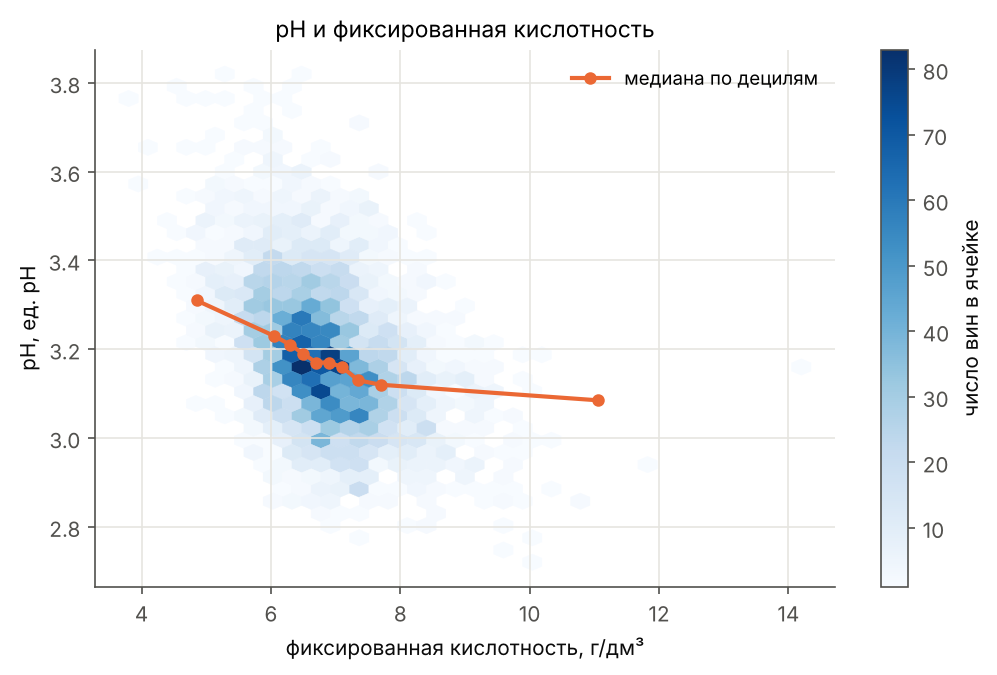

In [11]:
plots.scatter_dependence(white.fixed_acidity.to_numpy(), white.ph.to_numpy(),
                         "фиксированная кислотность, г/дм³", "pH, ед. pH",
                         "pH и фиксированная кислотность", "rv01_rv02_dependence.png");

<a id="fig4"></a>
*Рис. 4. Совместное распределение pH и фиксированной кислотности (цвет: число вин в ячейке) и медиана pH по децилям кислотности.*

**Результаты:**

- **pH и фиксированная кислотность:** Пирсон −0.43, Спирмен −0.42, Кендалл −0.29, все $p < 10^{-198}$. $\chi^2$ на таблице 4×4 = 792 при $\mathrm{df} = 9$, $p \approx 10^{-164}$, $V$ Крамера 0.23. Перестановочный тест: ни одна из 2000 перестановок не дала $|\rho|$ больше 0.061 (наблюдаемое 0.418), $p = 1/2001$. $H_0$ о независимости отвергается всеми тремя способами.
- Таблица сопряжённости: среди вин нижнего квартиля кислотности 567 из верхнего квартиля pH и 123 из нижнего.
- **pH и спирт:** $\rho = +0.15$, $\chi^2 = 236$ при $\mathrm{df} = 9$, $p \approx 10^{-46}$, $V$ Крамера 0.13. $H_0$ о независимости отвергается.

<a id="rv01-cons"></a>
#### 2.3.2 Состоятельность оценок

Из совокупности берём выборки объёма $n$ с возвращением (1000 повторов на каждое $n$) и смотрим, как оценка приближается к значению параметра в совокупности.

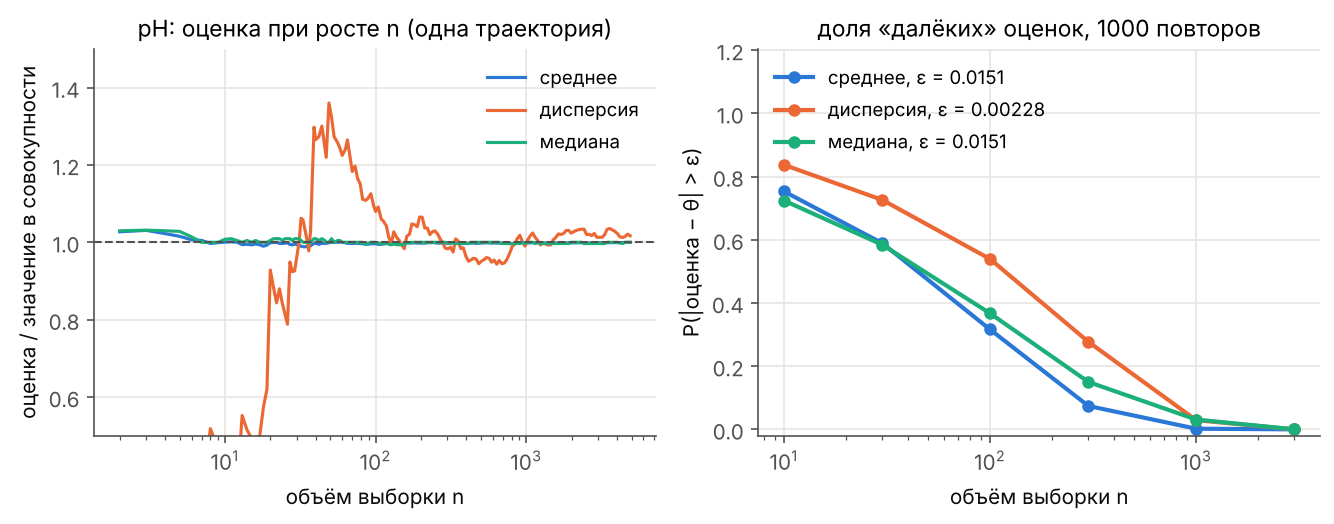

,оценка,n,theta,bias,sd_est,p_far,eps
0,mean,10,3.1883,-1.1986e-03,0.0472,0.753,0.0151
1,mean,30,3.1883,-1.7697e-04,0.0269,0.589,0.0151
2,mean,100,3.1883,2.6626e-04,0.0148,0.316,0.0151
3,mean,300,3.1883,9.7894e-05,0.0087,0.074,0.0151
4,mean,1000,3.1883,-1.5005e-04,0.0047,0.002,0.0151
5,mean,3000,3.1883,1.7322e-04,0.0027,0.000,0.0151
0,var,10,0.0228,1.3811e-04,0.0117,0.837,0.0023
1,var,30,0.0228,1.2134e-04,0.0067,0.726,0.0023
2,var,100,0.0228,-6.5264e-05,0.0037,0.539,0.0023
3,var,300,0.0228,4.5272e-05,0.0021,0.277,0.0023


In [12]:
ns = [10, 30, 100, 300, 1000, 3000]
curves_rv01 = {e: estimation.consistency_curve(x_rv01, e, ns, reps=1000, seed=SEED) for e in ["mean", "var", "median"]}
running_rv01 = {e: estimation.running_estimate(x_rv01, e, n_max=4898, seed=SEED) for e in ["mean", "var", "median"]}
plots.consistency_panel(curves_rv01, running_rv01, "pH", "rv01_consistency.png")
pd.concat(curves_rv01, names=["оценка"]).reset_index(level=0)[["оценка", "n", "theta", "bias", "sd_est", "p_far", "eps"]]

<a id="fig5"></a>
*Рис. 5. pH: траектория оценок при росте $n$ (слева) и доля оценок, отклонившихся от значения в совокупности больше чем на $\varepsilon$ (справа).*

**Результаты:**

- $\varepsilon = 0.1\,\sigma$ для среднего и медианы (0.0151), $\varepsilon = 0.1\,\sigma^2$ для дисперсии.
- Доля оценок дальше $\varepsilon$ от значения в совокупности при $n = 10 \to 3000$: среднее 0.75 → 0.00, медиана 0.72 → 0.00, несмещённая дисперсия 0.84 → 0.00.
- СКО оценки среднего: 0.047 при $n = 10$, 0.0027 при $n = 3000$ ($\sigma/\sqrt{3000} = 0.0028$).
- Смещение среднего и дисперсии в пределах ±0.0012 и меняет знак от $n$ к $n$: это случайный разброс по 1000 повторам; смещение медианы около −0.003 при всех $n$.

<a id="rv01-norm"></a>
### 2.4 Normalization

<sub>[↑ к содержанию](#toc)</sub>

после z: среднее -1.20e-15, СКО 1.000
доля |z| ≤ 1, 2, 3: [np.float64(0.694), np.float64(0.9573), np.float64(0.9935)] у N(0,1): [0.6827, 0.9545, 0.9973]


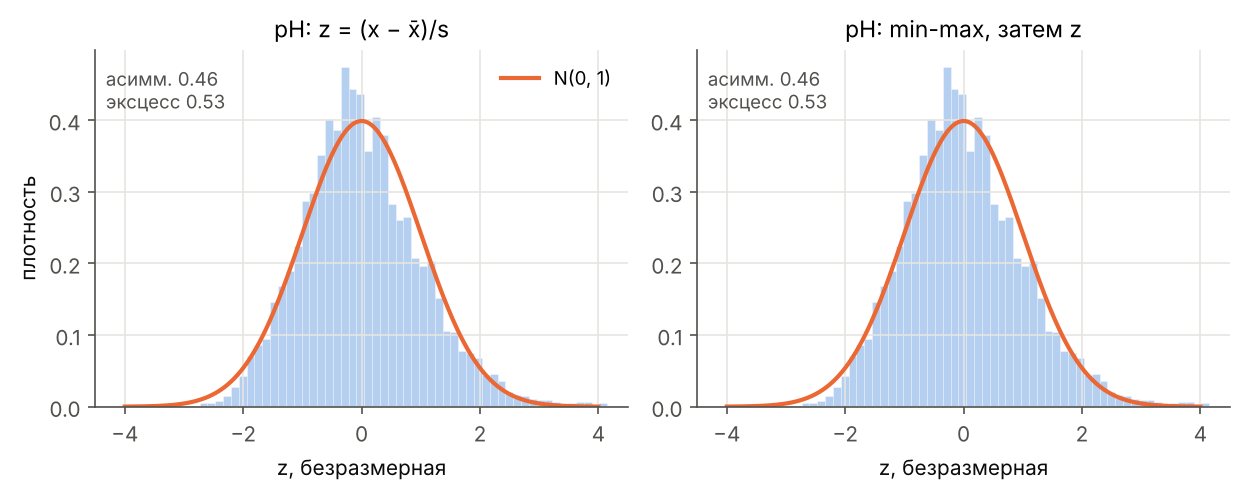

In [13]:
z_ph = normalize.zscore(x_rv01)
pairs = {"pH: z = (x − x̄)/s": z_ph, "pH: min-max, затем z": normalize.zscore(normalize.minmax(x_rv01))}
plots.normalization_panel(pairs, "rv01_normalization.png")
print(f"после z: среднее {z_ph.mean():.2e}, СКО {z_ph.std(ddof=1):.3f}")
print("доля |z| ≤ 1, 2, 3:", [round(np.mean(np.abs(z_ph) <= k), 4) for k in (1, 2, 3)], "у N(0,1): [0.6827, 0.9545, 0.9973]")

<a id="fig6"></a>
*Рис. 6. pH: распределение после преобразования в сравнении с плотностью $N(0, 1)$.*

**Результаты:**

- После z-преобразования: среднее 0 (до $10^{-15}$), СКО 1.000, асимметрия и эксцесс те же (0.46 и 0.53). Это стандартизация.
- Доли $|z| \le 1, 2, 3$: 0.694, 0.957, 0.9935; у $N(0, 1)$: 0.683, 0.954, 0.9973.
- Min-max, затем z: та же гистограмма, что после z.

**Зачем и как.** Стандартизация $z = (x - \bar x)/s$ переводит pH в число стандартных отклонений от среднего: у новой величины среднее 0 и СКО 1. Это линейное преобразование, оно только сдвигает шкалу и меняет её масштаб, поэтому форма распределения не меняется, асимметрия и эксцесс остаются прежними. Нужно это, чтобы сравнивать величины в разных единицах на одной шкале и пользоваться таблицами $N(0, 1)$; на том же переходе через $Z \sim N(0,1)$ построен датчик во втором спринте. Но pH не нормален (раздел 2.6), поэтому $z$ совпадает с $N(0, 1)$ только приближённо: это видно по долям $|z| \le 3$ (0.9935 против 0.9973).

<a id="rv01-sample"></a>
### 2.5 Sample vs Population

Одна выборка $n = 300$ (около 6 % совокупности) двумя способами, затем повторный эксперимент для разных $n$.

<sub>[↑ к содержанию](#toc)</sub>

КС выборка против совокупности: с возвращением p = 0.874, без возвращения p = 0.938
Повторов элементов в выборке с возвращением: 11


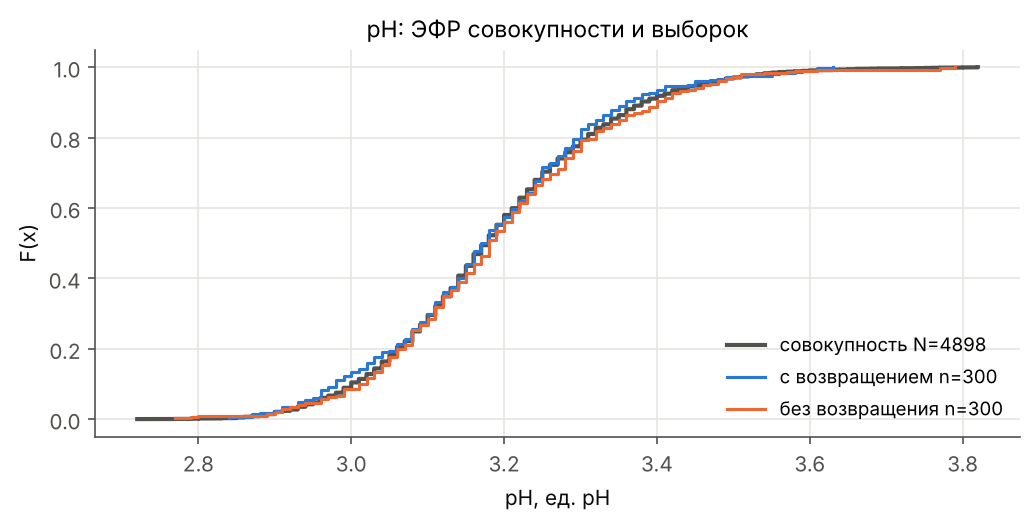

,n,mean,std,median,q25,q75,skew,kurt,ДИ 95% для среднего
совокупность,4898.0,3.1883,0.1510,3.180,3.09,3.28,0.4576,0.5290,
с возвращением,300.0,3.1801,0.1497,3.175,3.08,3.28,0.2886,0.1591,"[3.1631, 3.1971]"
без возвращения,300.0,3.1944,0.1564,3.180,3.08,3.29,0.4234,0.7626,"[3.1772, 3.2116]"


In [14]:
n = 300
s_with_rv01 = sampling.draw(x_rv01, n, replace=True, seed=SEED)
s_without_rv01 = sampling.draw(x_rv01, n, replace=False, seed=SEED)
tab = dsc.compare_table({"совокупность": x_rv01, "с возвращением": s_with_rv01, "без возвращения": s_without_rv01}).T
tab["ДИ 95% для среднего"] = ["", np.round(sampling.ci_mean(s_with_rv01), 4), np.round(sampling.ci_mean(s_without_rv01, N=len(x_rv01)), 4)]
ks_w, ks_wo = stats.ks_2samp(s_with_rv01, x_rv01), stats.ks_2samp(s_without_rv01, x_rv01)
print(f"КС выборка против совокупности: с возвращением p = {ks_w.pvalue:.3f}, без возвращения p = {ks_wo.pvalue:.3f}")
print("Повторов элементов в выборке с возвращением:", n - len(np.unique(sampling.draw(np.arange(len(x_rv01)), n, True, SEED))))
plots.sampling_panel(x_rv01, s_with_rv01, s_without_rv01, "pH", "ед. pH", "rv01_sampling.png")
tab[["n", "mean", "std", "median", "q25", "q75", "skew", "kurt", "ДИ 95% для среднего"]]

<a id="fig7"></a>
*Рис. 7. pH: эмпирические функции распределения совокупности и двух выборок $n = 300$.*

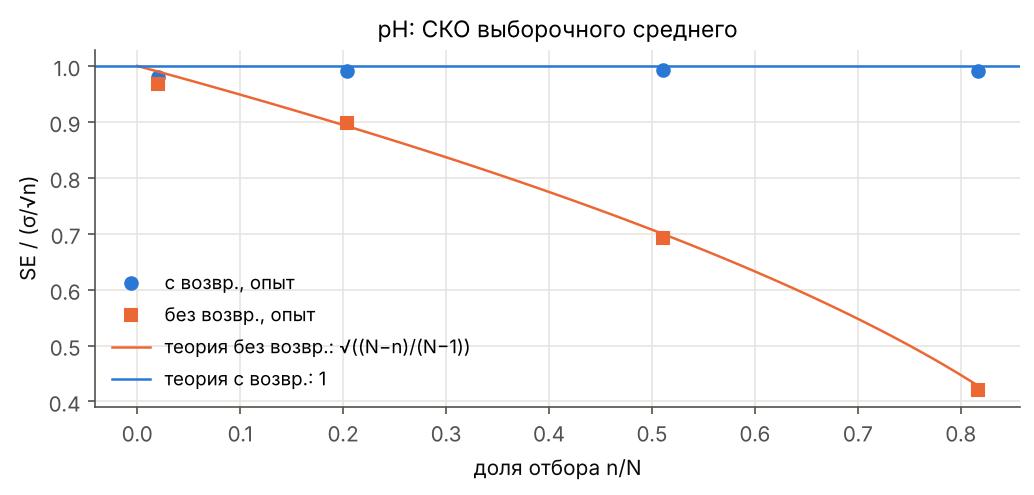

,n,n/N,se_with_emp,se_with_theory,se_without_emp,se_without_theory
0,100,0.0204,0.0148,0.0151,0.0146,0.0149
1,1000,0.2042,0.0047,0.0048,0.0043,0.0043
2,2500,0.5104,0.0030,0.0030,0.0021,0.0021
3,4000,0.8167,0.0024,0.0024,0.0010,0.0010


In [15]:
se_rv01 = sampling.se_mean_experiment(x_rv01, [100, 1000, 2500, 4000], reps=2000, seed=SEED)
plots.se_panel({"pH": se_rv01}, "rv01_se.png")
se_rv01

<a id="fig8"></a>
*Рис. 8. pH: СКО выборочного среднего при отборе с возвращением и без, в долях $\sigma/\sqrt{n}$.*

**Результаты:**

- Выборка $n = 300$: среднее 3.180 (с возвращением) и 3.194 (без) при 3.188 в совокупности. 95 % ДИ: [3.163; 3.197] и [3.177; 3.212], оба накрывают 3.188.
- КС «выборка против совокупности»: $p = 0.87$ и 0.94. (Выборка является частью совокупности, поэтому этот критерий здесь только иллюстрация.)
- В выборке с возвращением 11 вин попали дважды (ожидаемое число около $n^2/2N \approx 9$).
- 2000 повторов: с возвращением СКО среднего совпадает с $\sigma/\sqrt{n}$ при всех $n$. Без возвращения совпадает с $\frac{\sigma}{\sqrt{n}}\sqrt{\frac{N-n}{N-1}}$: при $n = 4000$ 0.0010 против 0.0024; при $n = 100$ 0.0146 против 0.0148.

<a id="rv01-hyp"></a>
### 2.6 Hypotheses

Уровень значимости $\alpha = 0.05$ для каждой проверки; поправка на множественность в [Lab resume](#resume).

<sub>[↑ к содержанию](#toc)</sub>

,данные,test,H0,p,решение
0,все 4898,D'Agostino K²,X ~ нормальное,1.0892e-42,отвергаем H0
1,все 4898,"χ² Пирсона, 19 интервалов, df 16",X ~ нормальное,1.1098e-14,отвергаем H0
2,все 4898,"КС, параметрический бутстреп с округлением",X ~ нормальное,3.3223e-03,отвергаем H0
3,выборка 200,D'Agostino K²,X ~ нормальное,1.3908e-01,нет оснований отвергнуть H0
4,выборка 200,Shapiro–Wilk,X ~ нормальное,7.0652e-02,нет оснований отвергнуть H0
5,все 4898,"χ² Пирсона, 19 интервалов, df 15",X ~ логнормальное со сдвигом,5.5549e-02,нет оснований отвергнуть H0


{'test': 'Welch t', 'H0': 'E[A] = E[B]', 'stat': -27.775496831893292, 'p': 2.3422645384856133e-149, 'decision': 'отвергаем H0', 'diff': -0.12284655630267016}


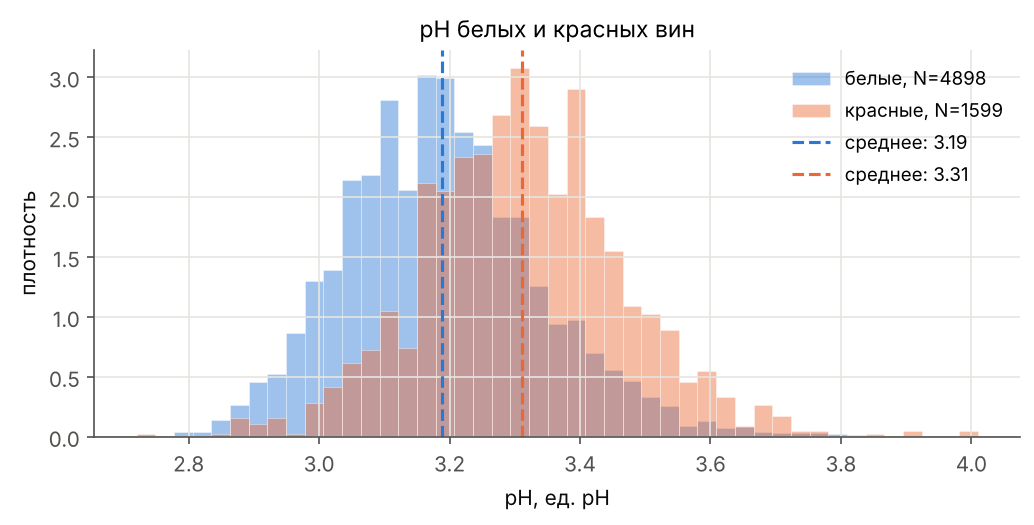

In [16]:
# H1: pH белых вин распределён нормально; H1b: pH ~ логнормальное со сдвигом
sub = sampling.draw(x_rv01, 200, replace=False, seed=SEED)
chi_norm_rv01 = dist.chi2_gof(x_rv01, "norm")          # параметры по интервалам, границы на полушагах 0.005
chi_lognorm_rv01 = dist.chi2_gof(x_rv01, "lognorm")
ks_rv01 = dist.ks_bootstrap(x_rv01, "norm", B=300, seed=SEED)   # бутстреп-выборки округляются до 0.01
rows = [
    hyp.normality_dagostino(x_rv01) | {"данные": "все 4898"},
    chi_norm_rv01 | {"test": f"χ² Пирсона, {chi_norm_rv01['bins']} интервалов, df {chi_norm_rv01['dof']}", "H0": "X ~ нормальное", "данные": "все 4898"},
    ks_rv01 | {"test": "КС, параметрический бутстреп с округлением", "H0": "X ~ нормальное", "данные": "все 4898"},
    hyp.normality_dagostino(sub) | {"данные": "выборка 200"},
    hyp.shapiro(sub) | {"данные": "выборка 200"},
    chi_lognorm_rv01 | {"test": f"χ² Пирсона, {chi_lognorm_rv01['bins']} интервалов, df {chi_lognorm_rv01['dof']}", "H0": "X ~ логнормальное со сдвигом", "данные": "все 4898"},
]
h_rv01 = pd.DataFrame(rows)[["данные", "test", "H0", "p"]]
h_rv01["решение"] = np.where(h_rv01.p < 0.05, "отвергаем H0", "нет оснований отвергнуть H0")
display(h_rv01)

# H2: средний pH белых и красных вин одинаков
h2 = hyp.welch_t(white.ph, red.ph)
print(h2)
plots.two_groups(white.ph.to_numpy(), red.ph.to_numpy(), "белые, N=4898", "красные, N=1599",
                 "pH, ед. pH", "pH белых и красных вин", "rv01_white_vs_red.png");

<a id="fig9"></a>
*Рис. 9. Распределение pH белых и красных вин, пунктир: средние.*

In [17]:
# Калибровка критериев: данные, которые ТОЧНО нормальны, с теми же μ, σ, N и округлением до 0.01.
# Правильный критерий отвергает H0 примерно в 5 % таких случаев.
calib_rv01 = dist.calibration("norm", (x_rv01.mean(), x_rv01.std()), n=len(x_rv01), step=0.01, sims=200, B=99, seed=SEED)
pd.Series(calib_rv01)

chi2_reject_rate      0.035
chi2_sims           200.000
ks_reject_rate        0.020
ks_sims              50.000
dtype: float64

**Результаты:**

- **H1 (pH нормален), все 4898:** $K^2$ $p \approx 10^{-42}$; $\chi^2$ (19 интервалов, $\mathrm{df} = 16$) $p \approx 10^{-14}$; КС с параметрическим бутстрепом $p = 0.003$ (ни одна из 300 бутстреп-выборок не дала $D$ больше наблюдаемого). $H_0$ отвергается.
- **H1 на случайной выборке 200:** $K^2$ $p = 0.14$, Шапиро–Уилк $p = 0.07$. $H_0$ не отвергается.
- **H1b (pH логнормален со сдвигом):** $\chi^2$ (19 интервалов, $\mathrm{df} = 15$) $p = 0.056$. $H_0$ не отвергается. Семейство выбрано после просмотра таблицы AIC.
- **H2 (средний pH белых = красных):** $t$ Уэлча $= -27.8$, $p \approx 10^{-149}$, разница −0.123. $H_0$ отвергается.
- **Калибровка критериев** на 200 симулированных нормальных наборах с теми же $\mu$, $\sigma$, $N$ и округлением 0.01: $\chi^2$ отверг $H_0$ в 3.5 % случаев, КС-бутстреп в 2 % (50 наборов). Номинал 5 %.

<a id="rv01-resume"></a>
### 2.7 Resume

<sub>[↑ к содержанию](#toc)</sub>

**Вывод по pH.**

1. pH случайно выбранного вина нельзя узнать заранее: по 10 другим измерениям его можно угадать только примерно ($R^2 = 0.50$), потому что в датасете есть не весь состав вина.
2. Распределение pH похоже на колокол, но не совсем нормальное: правый хвост длиннее (асимметрия +0.46). На всех винах нормальность отвергается, а лучше подходят логнормальное со сдвигом и скошенное нормальное. Логнормальное выбрано после просмотра таблицы AIC (информационный критерий Акаике: чем меньше число, тем лучше модель описывает данные), поэтому $p = 0.056$ завышено: семейство подбирали по тем же данным, и «не отвергнуто» здесь ненадёжно.
3. pH связан с кислотностью: прослеживается зависимость, чем больше в вине кислот, тем ниже pH ($\rho = -0.42$). Со спиртом связь слабая ($\rho = +0.15$).
4. По 300 винам можно судить обо всех винах, так как среднее выборки уже похоже на правду: 3.18–3.19 при 3.188 у всех вин. Чем больше выборка, тем точнее оценки.
5. pH у белых вин ниже, чем у красных, на 0.12, хотя кислот у красных больше (8.32 против 6.85 г/дм³). Значит, pH зависит не только от количества кислот. Возможное объяснение по литературе [8]: красное вино настаивают на кожице винограда, из неё переходит калий, который связывает часть кислот, а ещё в красных чаще проводят яблочно-молочное брожение. Калий в датасете не измерен, поэтому по нашим данным это не проверить.

<a id="rv02"></a>
## 3. Random Variable 02 (фиксированная кислотность)

<sub>[↑ к содержанию](#toc)</sub>

<a id="rv02-desc"></a>
### 3.1 Description (природа события)

**Величина.** Фиксированная (нелетучая) кислотность, г/дм³ в пересчёте на винную кислоту, определяется титрованием, записана с шагом 0.1. Как и pH, характеризует кислотность вина, поэтому для пары RV01–RV02 проверяется зависимость.

**Событие.** Случайно выбирается образец белого вина, у него измерена кислотность.

**Что посчитано.** Те же проверки, что для pH: линейный прогноз и $k$ ближайших соседей по 10 другим измерениям, поиск «двойников».

**Природа события.** Количество кислот в вине зависит от сорта винограда, его зрелости и погоды: в прохладный год виноград кислее [11, гл. «Органические кислоты»]. Кислотность и pH одной природы, обе про кислоты, но это не одно и то же: кислотность показывает количество кислоты в вине, а pH показывает, сколько ионов водорода свободно в вине. Часть кислот связана солями калия, которые работают как буфер, поэтому при одинаковом количестве кислот pH может быть разным. Поэтому они связаны ($\rho = -0.42$), но одна не определяет другую полностью. По справочнику по виноделию, в столовых винах титруемая кислотность составляет 5.0–8.0 г/дм³ [12]; средняя кислотность наших вин 6.85 г/дм³ попадает в этот диапазон. Кислотность случайно выбранного вина нельзя узнать заранее: по 10 другим измерениям её можно угадать только примерно ($R^2 = 0.58$, ошибка 0.54 г/дм³ в 5 раз больше шага прибора 0.1). Это видно и по «двойникам»: нашлось 18 групп вин, у которых все остальные 10 измерений совпадают, а кислотность разная. Почти все такие вина стоят в таблице рядом, скорее всего это повторные измерения одного вина, и разница 0.1–0.3 г/дм³ показывает случайную погрешность измерения. Если бы кислотность вычислялась как зависимая от других измерений, то у одинаковых вин она тоже была бы одинаковой, хотя это не так.

<sub>[↑ к содержанию](#toc)</sub>

Линейная модель: R² на кросс-валидации 0.584, СКО остатка 0.5446 г/дм³
k ближайших соседей, k = 5: R² 0.472, СКО остатка 0.6135 г/дм³
k ближайших соседей, k = 15: R² 0.433, СКО остатка 0.6355 г/дм³
k ближайших соседей, k = 30: R² 0.401, СКО остатка 0.6533 г/дм³
Шаг записи прибора: 0.1 г/дм³; СКО самой величины: 0.8439
Групп вин с одинаковыми остальными 10 измерениями, но разным значением: 18


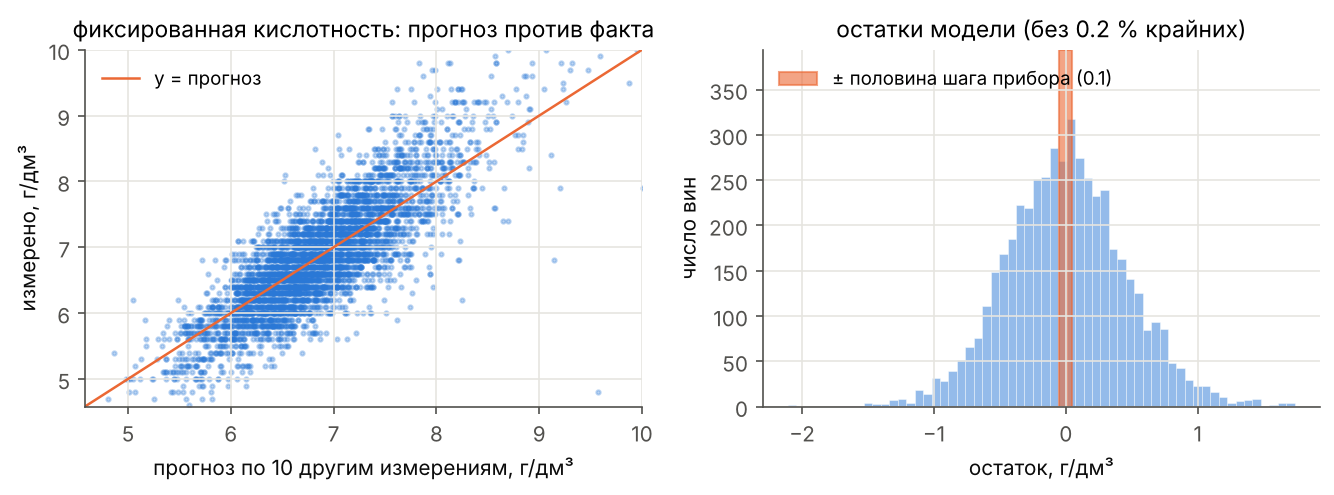

,nunique,min,max,count
0,2,6.4,6.5,2
1,2,5.4,5.6,3
2,2,5.5,5.6,2
3,2,5.4,5.6,2
4,2,4.9,5.0,2


In [18]:
res_rv02 = stochastic.cv_r2_linear(X.drop(columns="fixed_acidity"), X["fixed_acidity"], k=5, seed=SEED)
knn_rv02 = {kk: stochastic.cv_r2_knn(X.drop(columns="fixed_acidity"), X["fixed_acidity"], k_neighbors=kk, k=5, seed=SEED) for kk in (5, 15, 30)}
twins_rv02 = stochastic.same_inputs_different_target(X, "fixed_acidity")
print(f"Линейная модель: R² на кросс-валидации {res_rv02['r2_cv']:.3f}, СКО остатка {res_rv02['resid_std']:.4f} г/дм³")
for kk, r in knn_rv02.items():
    print(f"k ближайших соседей, k = {kk}: R² {r['r2_cv']:.3f}, СКО остатка {r['resid_std']:.4f} г/дм³")
print(f"Шаг записи прибора: 0.1 г/дм³; СКО самой величины: {X['fixed_acidity'].std():.4f}")
print(f"Групп вин с одинаковыми остальными 10 измерениями, но разным значением: {len(twins_rv02)}")
plots.stochastic_panel(X["fixed_acidity"].to_numpy(), res_rv02["resid"], "фиксированная кислотность", "г/дм³", 0.1, "rv02_stochastic.png");
twins_rv02.head()

<a id="fig10"></a>
*Рис. 10. Фиксированная кислотность: прогноз по 10 другим измерениям против измеренного значения (слева) и остатки модели в сравнении с шагом записи прибора (справа).*

**Результаты:**

- Линейная модель: $R^2$ 0.58, СКО остатка 0.54 г/дм³. $k$ ближайших соседей: $R^2$ 0.47 / 0.43 / 0.40 при $k = 5 / 15 / 30$, СКО остатка 0.61–0.65.
- Шаг записи 0.1 г/дм³, СКО самой величины 0.84.
- 18 групп вин с одинаковыми остальными 10 измерениями и разной кислотностью; разница в группах от 0.1 до 0.3 г/дм³ (например, 5.4 и 5.6), в одной группе 6.8 г/дм³: 14.2 против 7.4 при совпадении всех остальных измерений. Это максимум всей таблицы и, скорее всего, ошибка записи; без этого значения эксцесс кислотности 1.13 вместо 2.17 (пересчёт `scipy.stats.kurtosis` без этой строки).

<a id="rv02-eda"></a>
### 3.2 EDA & Distribution

<sub>[↑ к содержанию](#toc)</sub>

In [19]:
x_rv02 = white["fixed_acidity"].to_numpy()
out_rv02 = dsc.iqr_outliers(x_rv02)
print("Выбросов по правилу 1.5·IQR:", out_rv02.sum(), f"({out_rv02.mean():.1%})")
dsc.compare_table({"белые, все": x_rv02, "белые без дублей": white.drop_duplicates()["fixed_acidity"], "красные": red["fixed_acidity"]}).T

Выбросов по правилу 1.5·IQR: 119 (2.4%)


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
"белые, все",4898.0,6.8548,0.7121,0.8439,0.1231,3.8,6.3,6.8,7.3,14.2,1.0,6.8,0.6476,2.1687,68.0,0.05
белые без дублей,3961.0,6.8393,0.7514,0.8669,0.1267,3.8,6.3,6.8,7.3,14.2,1.0,6.8,0.6958,2.2487,68.0,0.05
красные,1599.0,8.3196,3.0314,1.7411,0.2093,4.6,7.1,7.9,9.2,15.9,2.1,7.2,0.9818,1.1249,96.0,0.10


In [20]:
fit_rv02 = dist.fit_candidates(x_rv02)
fit_rv02

,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
skewnorm,3,-6017.3683,12040.7366,12060.2264,0.0419,"(1.8102, 6.0421, 1.1715)"
lognorm,3,-6019.1276,12044.2553,12063.7450,0.0439,"(0.1296, 0.4198, 6.381)"
gamma,3,-6027.0201,12060.0402,12079.5299,0.0435,"(32.4957, 2.0843, 0.1468)"
norm,2,-6117.9817,12239.9633,12252.9565,0.0662,"(6.8548, 0.8438)"
weibull_min,3,-6265.6653,12537.3306,12556.8203,0.0724,"(3.7074, 3.7835, 3.3833)"


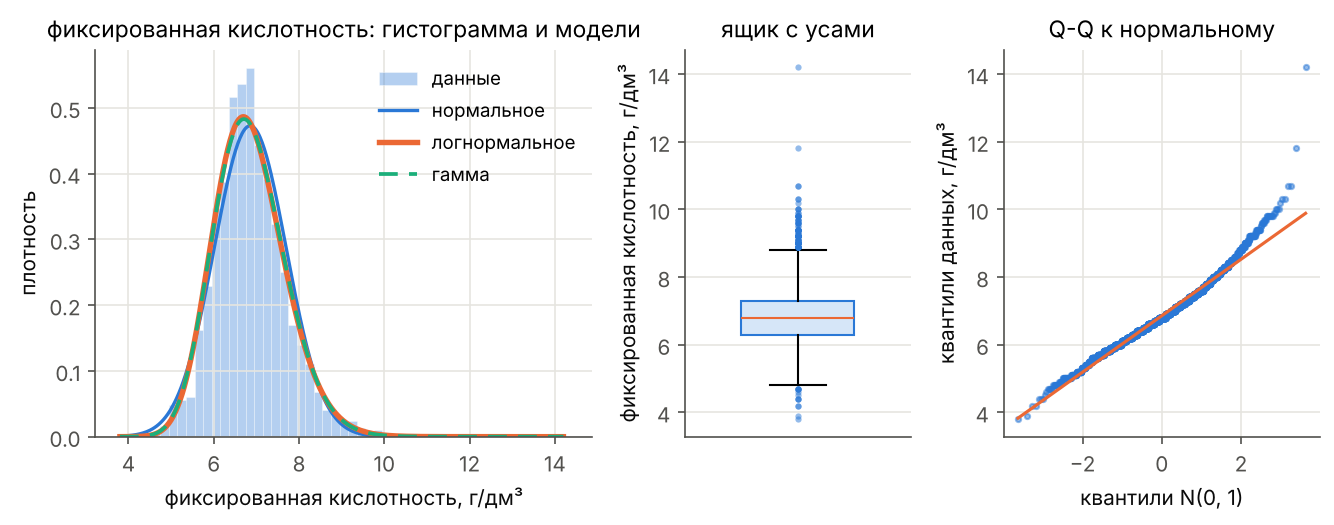

In [21]:
best_rv02 = {name: dist.fit(name, x_rv02) for name in ['norm', 'lognorm', 'gamma']}
plots.eda_panel(x_rv02, "фиксированная кислотность", "г/дм³", best_rv02, "rv02_eda.png");

<a id="fig11"></a>
*Рис. 11. Фиксированная кислотность: гистограмма с подобранными плотностями, ящик с усами и Q-Q-график к нормальному распределению.*

**Результаты:**

- Среднее 6.85, медиана 6.8, мода 6.8 г/дм³, СКО 0.84, КВ 12 %.
- Асимметрия +0.65, эксцесс +2.17. Выбросов 119 (2.4 %), максимум 14.2 при Q3 = 7.3.
- AIC: скошенная нормальная 12040.7, логнормальная со сдвигом 12044.3, гамма 12060.0, нормальная 12240.0. Оценка сдвига логнормальной 0.42 г/дм³.
- Красные вина: 8.32 ± 1.74 г/дм³.

<a id="rv02-math"></a>
#### 3.2.1 Математическое описание распределения

**Проверяемое семейство: логнормальное распределение** [2, 4]. Справочные формулы. $X$ логнормальна, если $\ln X \sim N(\mu, \sigma^2)$. Трёхпараметрическая форма со сдвигом $\theta$ (в scipy: `s` = $\sigma$, `loc` = $\theta$, `scale` = $e^{\mu}$):

$$f(x) = \frac{1}{(x-\theta)\,\sigma\sqrt{2\pi}}\exp\left(-\frac{(\ln(x-\theta)-\mu)^2}{2\sigma^2}\right),\quad x > \theta.$$

- Моменты (при $\theta = 0$): $E X = e^{\mu+\sigma^2/2}$, $D X = (e^{\sigma^2}-1)\,e^{2\mu+\sigma^2}$, медиана $e^{\mu}$, мода $e^{\mu-\sigma^2}$, т. е. мода < медиана < среднее.
- Асимметрия $(e^{\sigma^2}+2)\sqrt{e^{\sigma^2}-1} > 0$.
- Нормализация: $Z = (\ln(X-\theta) - \mu)/\sigma \sim N(0, 1)$.

В разделе Hypotheses проверяются оба варианта: без сдвига (H3, через нормальность $\ln X$) и со сдвигом (H3b, $\chi^2$).

**Почему проверялось логнормальное распределение.** Для кислотности взяли логнормальное распределение, так как нормальный колокол может уходить в минус, а кислотность у нас не бывает отрицательной; у логнормального все значения положительные. Также гистограмма кислотности несимметрична (асимметрия +0.65, длинный хвост вправо до 14.2 г/дм³), а нормальный колокол симметричен. После логарифмирования наш скошенный колокол стал больше похож на обычный: асимметрия упала с 0.65 до 0.08. По таблице AIC логнормальное распределение лучше нормального (12044 против 12240), но точно оно не подходит: проверки отвергают и логнормальное без сдвига ($p \approx 10^{-21}$), и со сдвигом ($p \approx 3\cdot 10^{-6}$). Лучшей по AIC оказалась скошенная нормальная (12040.7), но критерием согласия мы её не проверяли. Реальная форма кислотности сложнее любой из простых формул, а на 4898 винах критерий замечает даже небольшие отличия.

<a id="rv02-indep"></a>
### 3.3 Independence & Estimations

<a id="rv02-dep"></a>
#### 3.3.1 Зависимость

Корреляции (Пирсон, Спирмен, Кендалл), хи-квадрат на таблице сопряжённости по квартилям и перестановочный тест.

<sub>[↑ к содержанию](#toc)</sub>

In [22]:
print("фиксированная кислотность и pH")
display(dependence.correlations(white["fixed_acidity"], white["ph"]))
chi = dependence.chi2_independence(white["fixed_acidity"], white["ph"], bins=4)
perm = dependence.permutation_spearman(white["fixed_acidity"], white["ph"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

фиксированная кислотность и pH


,coef,p
method,,
pearson,-0.4259,4.8420e-215
spearman,-0.4183,7.9855e-207
kendall,-0.2948,5.2617e-199


χ² = 792.0, df = 9, p = 1.11e-164, V Крамера = 0.232
перестановочный тест: ρ = -0.418, p = 0.0005, |ρ| при H0 не больше 0.051


ph,0,1,2,3
fixed_acidity,,,,
0,123,220,385,567
1,296,395,353,296
2,332,277,237,213
3,563,354,181,106


In [23]:
print("фиксированная кислотность и спирт")
display(dependence.correlations(white["fixed_acidity"], white["alcohol"]))
chi = dependence.chi2_independence(white["fixed_acidity"], white["alcohol"], bins=4)
perm = dependence.permutation_spearman(white["fixed_acidity"], white["alcohol"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

фиксированная кислотность и спирт


,coef,p
method,,
pearson,-0.1209,2.0854e-17
spearman,-0.1068,6.5824e-14
kendall,-0.0732,8.7284e-14


χ² = 94.6, df = 9, p = 1.98e-16, V Крамера = 0.080
перестановочный тест: ρ = -0.107, p = 0.0005, |ρ| при H0 не больше 0.052


alcohol,0,1,2,3
fixed_acidity,,,,
0,300,267,333,395
1,444,322,284,290
2,347,220,265,227
3,345,328,308,223


**Результаты:**

- **С pH:** те же числа, что в RV01 ($\rho = -0.42$, $\chi^2 = 792$, $V = 0.23$).
- **Со спиртом:** $\rho = -0.11$, $\chi^2 = 94.6$ при $\mathrm{df} = 9$, $p \approx 10^{-16}$, $V$ Крамера 0.08. $H_0$ о независимости отвергается.

<a id="rv02-cons"></a>
#### 3.3.2 Состоятельность оценок

Из совокупности берём выборки объёма $n$ с возвращением (1000 повторов на каждое $n$) и смотрим, как оценка приближается к значению параметра в совокупности.

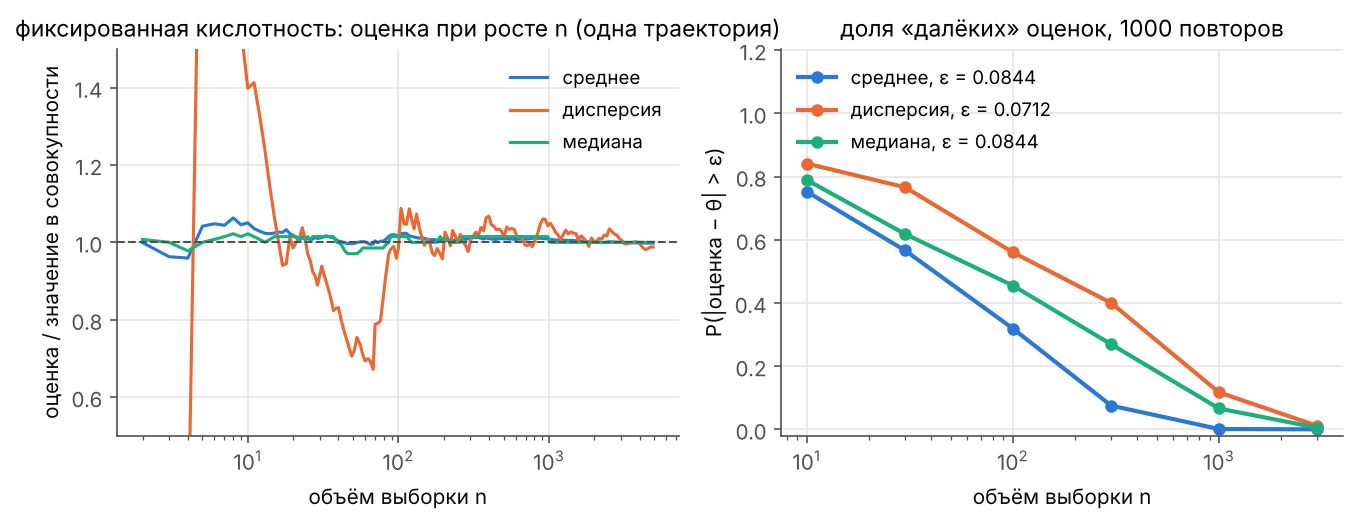

,оценка,n,theta,bias,sd_est,p_far,eps
0,mean,10,6.8548,-6.8177e-03,0.2624,0.752,0.0844
1,mean,30,6.8548,9.2907e-03,0.1498,0.566,0.0844
2,mean,100,6.8548,-2.2697e-03,0.0832,0.319,0.0844
3,mean,300,6.8548,-3.7334e-04,0.0476,0.075,0.0844
4,mean,1000,6.8548,1.2705e-03,0.0274,0.001,0.0844
5,mean,3000,6.8548,6.1132e-05,0.0153,0.000,0.0844
0,var,10,0.7120,3.2769e-02,0.4867,0.841,0.0712
1,var,30,0.7120,5.5024e-03,0.2657,0.766,0.0712
2,var,100,0.7120,-6.0822e-03,0.1304,0.560,0.0712
3,var,300,0.7120,2.0691e-03,0.0873,0.400,0.0712


In [24]:
ns = [10, 30, 100, 300, 1000, 3000]
curves_rv02 = {e: estimation.consistency_curve(x_rv02, e, ns, reps=1000, seed=SEED) for e in ["mean", "var", "median"]}
running_rv02 = {e: estimation.running_estimate(x_rv02, e, n_max=4898, seed=SEED) for e in ["mean", "var", "median"]}
plots.consistency_panel(curves_rv02, running_rv02, "фиксированная кислотность", "rv02_consistency.png")
pd.concat(curves_rv02, names=["оценка"]).reset_index(level=0)[["оценка", "n", "theta", "bias", "sd_est", "p_far", "eps"]]

<a id="fig12"></a>
*Рис. 12. Фиксированная кислотность: траектория оценок при росте $n$ (слева) и доля оценок, отклонившихся от значения в совокупности больше чем на $\varepsilon$ (справа).*

**Результаты:**

- $\varepsilon = 0.084$ г/дм³ для среднего и медианы, 0.071 для дисперсии.
- Доля «далёких» оценок при $n = 10 \to 3000$: среднее 0.75 → 0.00, медиана 0.79 → 0.005, дисперсия 0.84 → 0.011.
- Из трёх оценок дисперсия при $n = 1000$ и 3000 даёт наибольшую долю «далёких» (0.117 и 0.011).

<a id="rv02-norm"></a>
### 3.4 Normalization

<sub>[↑ к содержанию](#toc)</sub>

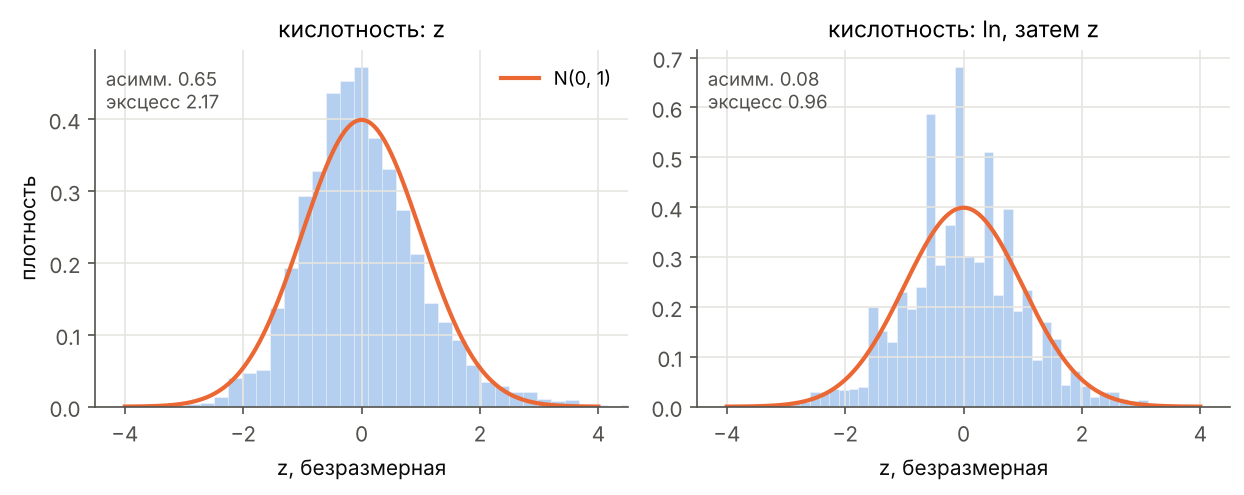

In [25]:
z_fa = normalize.zscore(x_rv02)
lz_fa = normalize.log_z(x_rv02)
plots.normalization_panel({"кислотность: z": z_fa, "кислотность: ln, затем z": lz_fa}, "rv02_normalization.png");

<a id="fig13"></a>
*Рис. 13. Фиксированная кислотность: распределение после преобразования в сравнении с плотностью $N(0, 1)$.*

**Результаты:**

- После z: асимметрия 0.65, эксцесс 2.17 (не изменились). После ln и z: асимметрия 0.08, эксцесс 0.96.

<a id="rv02-sample"></a>
### 3.5 Sample vs Population

Одна выборка $n = 300$ (около 6 % совокупности) двумя способами, затем повторный эксперимент для разных $n$.

<sub>[↑ к содержанию](#toc)</sub>

КС выборка против совокупности: с возвращением p = 0.354, без возвращения p = 1.000
Повторов элементов в выборке с возвращением: 11


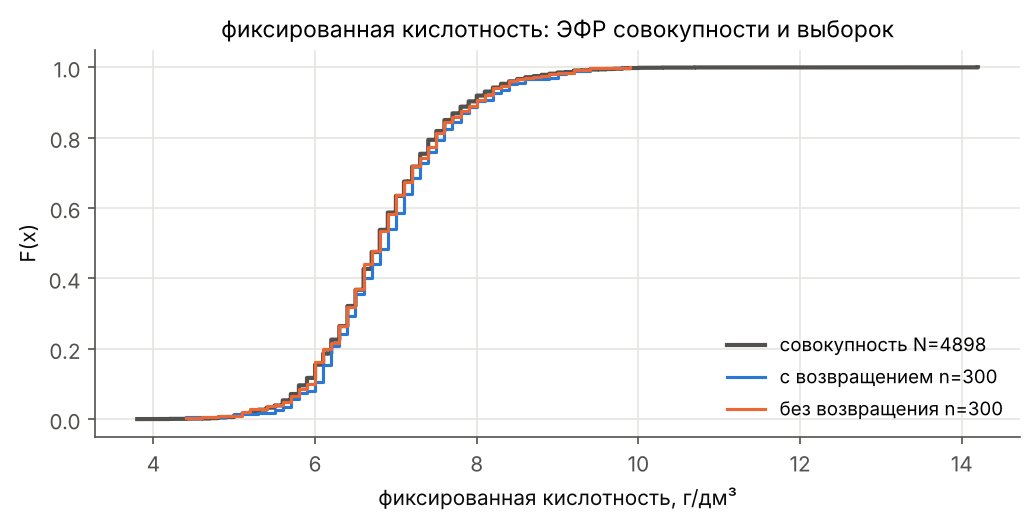

,n,mean,std,median,q25,q75,skew,kurt,ДИ 95% для среднего
совокупность,4898.0,6.8548,0.8439,6.8,6.3,7.3,0.6476,2.1687,
с возвращением,300.0,6.9390,0.8475,6.9,6.4,7.4,0.4428,0.7265,"[6.8427, 7.0353]"
без возвращения,300.0,6.8617,0.8528,6.8,6.3,7.4,0.4155,0.6760,"[6.7678, 6.9556]"


In [26]:
n = 300
s_with_rv02 = sampling.draw(x_rv02, n, replace=True, seed=SEED)
s_without_rv02 = sampling.draw(x_rv02, n, replace=False, seed=SEED)
tab = dsc.compare_table({"совокупность": x_rv02, "с возвращением": s_with_rv02, "без возвращения": s_without_rv02}).T
tab["ДИ 95% для среднего"] = ["", np.round(sampling.ci_mean(s_with_rv02), 4), np.round(sampling.ci_mean(s_without_rv02, N=len(x_rv02)), 4)]
ks_w, ks_wo = stats.ks_2samp(s_with_rv02, x_rv02), stats.ks_2samp(s_without_rv02, x_rv02)
print(f"КС выборка против совокупности: с возвращением p = {ks_w.pvalue:.3f}, без возвращения p = {ks_wo.pvalue:.3f}")
print("Повторов элементов в выборке с возвращением:", n - len(np.unique(sampling.draw(np.arange(len(x_rv02)), n, True, SEED))))
plots.sampling_panel(x_rv02, s_with_rv02, s_without_rv02, "фиксированная кислотность", "г/дм³", "rv02_sampling.png")
tab[["n", "mean", "std", "median", "q25", "q75", "skew", "kurt", "ДИ 95% для среднего"]]

<a id="fig14"></a>
*Рис. 14. Фиксированная кислотность: эмпирические функции распределения совокупности и двух выборок $n = 300$.*

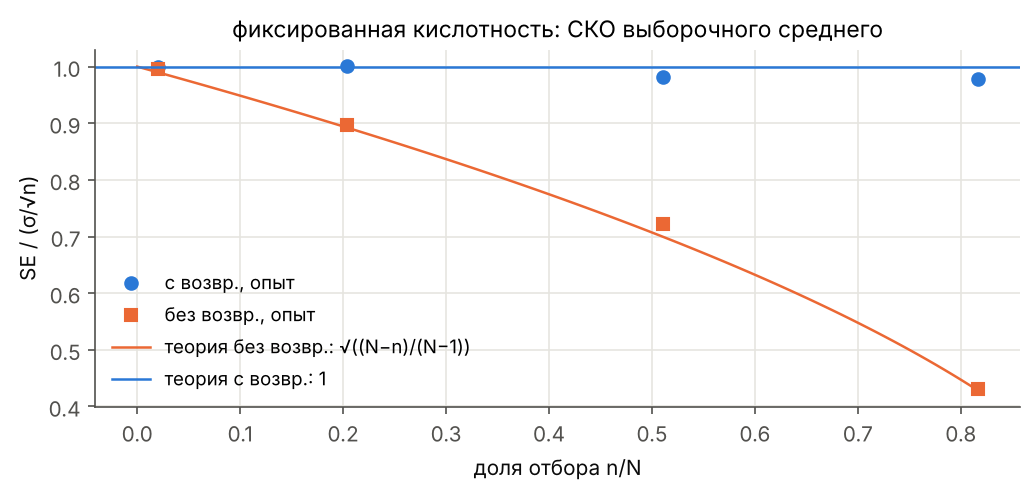

,n,n/N,se_with_emp,se_with_theory,se_without_emp,se_without_theory
0,100,0.0204,0.0843,0.0844,0.0841,0.0835
1,1000,0.2042,0.0267,0.0267,0.0239,0.0238
2,2500,0.5104,0.0166,0.0169,0.0122,0.0118
3,4000,0.8167,0.0130,0.0133,0.0058,0.0057


In [27]:
se_rv02 = sampling.se_mean_experiment(x_rv02, [100, 1000, 2500, 4000], reps=2000, seed=SEED)
plots.se_panel({"фиксированная кислотность": se_rv02}, "rv02_se.png")
se_rv02

<a id="fig15"></a>
*Рис. 15. Фиксированная кислотность: СКО выборочного среднего при отборе с возвращением и без, в долях $\sigma/\sqrt{n}$.*

**Результаты:**

- $n = 300$: среднее 6.94 (с возвращением) и 6.86 (без) при 6.85 в совокупности. Оба 95 % ДИ накрывают 6.85.
- Асимметрия и эксцесс в выборках 0.42–0.44 и 0.68–0.73 при 0.65 и 2.17 в совокупности. Эксцесс выборка занижает: его создают редкие крайние значения, а в 300 вин они почти не попадают.
- SE среднего без возвращения при $n = 4000$: 0.0058 против 0.0130 с возвращением; теория 0.0057.

<a id="rv02-hyp"></a>
### 3.6 Hypotheses

Уровень значимости $\alpha = 0.05$ для каждой проверки; поправка на множественность в [Lab resume](#resume).

<sub>[↑ к содержанию](#toc)</sub>

In [28]:
# H3: ln(кислотности) распределён нормально (кислотность логнормальна без сдвига)
# H3b: кислотность ~ логнормальное со сдвигом (3 параметра)
lx = np.log(x_rv02)
sub = sampling.draw(x_rv02, 200, replace=False, seed=SEED)
chi_ln_rv02 = dist.chi2_gof(lx, "norm", step=0)        # после логарифма сетка неравномерная, step=0
chi_ln3_rv02 = dist.chi2_gof(x_rv02, "lognorm")        # шаг 0.1 определяется по данным
rows = [
    hyp.normality_dagostino(lx) | {"H0": "ln X ~ нормальное", "данные": "ln X, все 4898"},
    chi_ln_rv02 | {"test": f"χ² Пирсона, {chi_ln_rv02['bins']} интервалов", "H0": "ln X ~ нормальное", "данные": "ln X, все 4898"},
    chi_ln3_rv02 | {"test": f"χ² Пирсона, {chi_ln3_rv02['bins']} интервалов, df {chi_ln3_rv02['dof']}", "H0": "X ~ логнормальное со сдвигом", "данные": "X, все 4898"},
    hyp.normality_dagostino(np.log(sub)) | {"H0": "ln X ~ нормальное", "данные": "ln X, выборка 200"},
    hyp.normality_dagostino(x_rv02) | {"H0": "X ~ нормальное", "данные": "X, все 4898"},
]
h_rv02 = pd.DataFrame(rows)[["данные", "test", "H0", "p"]]
h_rv02["решение"] = np.where(h_rv02.p < 0.05, "отвергаем H0", "нет оснований отвергнуть H0")
h_rv02

,данные,test,H0,p,решение
0,"ln X, все 4898",D'Agostino K²,ln X ~ нормальное,1.8880e-21,отвергаем H0
1,"ln X, все 4898","χ² Пирсона, 20 интервалов",ln X ~ нормальное,1.2739e-08,отвергаем H0
2,"X, все 4898","χ² Пирсона, 17 интервалов, df 13",X ~ логнормальное со сдвигом,3.0871e-06,отвергаем H0
3,"ln X, выборка 200",D'Agostino K²,ln X ~ нормальное,4.4889e-01,нет оснований отвергнуть H0
4,"X, все 4898",D'Agostino K²,X ~ нормальное,5.1923e-118,отвергаем H0


**Результаты:**

- **H3 ($\ln X$ нормален, логнормальное без сдвига):** $K^2$ $p \approx 10^{-21}$, $\chi^2$ $p \approx 10^{-8}$ на всех 4898. $H_0$ отвергается. На выборке 200: $K^2$ $p = 0.45$.
- **H3b (логнормальное со сдвигом):** $\chi^2$ (17 интервалов, $\mathrm{df} = 13$) $p \approx 3\cdot 10^{-6}$. $H_0$ отвергается.
- Для сравнения: X нормален, $K^2$ $p \approx 10^{-118}$. Статистика $K^2$ 540 для X и 95 для $\ln X$.

<a id="rv02-resume"></a>
### 3.7 Resume

<sub>[↑ к содержанию](#toc)</sub>

**Вывод по кислотности.**

1. Кислотность случайно выбранного вина нельзя узнать заранее: по другим измерениям её можно угадать только примерно ($R^2 = 0.58$), а 18 групп «двойников» с одинаковыми остальными измерениями имеют разную кислотность.
2. pH и кислотность оказались зависимыми величинами, это показали три способа. Корреляция проверяет общую тенденцию, то есть зависимость одной величины от другой: тут зависимость обратная, чем больше кислот, тем ниже pH ($\rho = -0.42$). Хи-квадрат делит вина на 4 группы по pH и 4 группы по кислотности и смотрит, как часто встречается каждая пара групп: если бы величины были независимы, каждое сочетание встречалось бы с частотой, равной произведению долей своих групп, а у нас некоторые сочетания встречаются намного чаще. Отличие от корреляции в том, что хи-квадрат замечает любую связь, а не только общую тенденцию. В перестановочном тесте pH перемешали, тем самым разорвав любую связь, и ни разу корреляция не вышла такой сильной, как настоящая.
3. Связь средняя, умеренная: $\rho = -0.42$ и $V$ Крамера 0.23 (сила связи по таблице с группами, от 0, когда связи нет, до 1, когда связь полная). На графике облако наклонено вниз, тёмное и плотное только в одном месте, а дальше рассеивается. Поэтому по кислотности pH угадывается лишь примерно.
4. Распределение кислотности несимметричное, с хвостом вправо. После логарифмирования оно стало почти симметричным (асимметрия 0.08), но логнормальная модель точно не подтвердилась ни без сдвига, ни со сдвигом.
5. Все оценки уточняются с ростом выборки, но дисперсия медленнее среднего и медианы: очень кислых вин мало, и попадут ли они в выборку, решает случай, а дисперсия считается через квадраты отклонений, поэтому один выброс сильно на неё влияет.

<a id="rv03"></a>
## 4. Random Variable 03 (спирт)

<sub>[↑ к содержанию](#toc)</sub>

<a id="rv03-desc"></a>
### 4.1 Description (природа события)

**Величина.** Объёмная доля этанола, % об., записана с шагом 0.1 (69 значений не на этой сетке, см. EDA датасета).

**Событие.** Случайно выбирается образец белого вина, у него измерено содержание спирта.

**Что посчитано.** Те же проверки: линейный прогноз и $k$ ближайших соседей по 10 другим измерениям, поиск «двойников».

**Природа события.** При брожении вина дрожжи съедают сахар из винограда и превращают его в спирт [11, гл. «Брожение виноградного сусла»]. На долю спирта влияют два фактора: количество сахара в винограде, которое зависит от зрелости и погоды, и то, насколько далеко зашло брожение. У спирта другая природа, в отличие от кислотности и pH, ведь спирт связан с совсем другими свойствами вина, с сахаром и брожением; поэтому и связь с ними слабая ($\rho = +0.15$ и $-0.11$). Спирт в любом случае случайная величина. Да, он сильно связан с плотностью: спирт легче воды, поэтому чем больше спирта, тем ниже плотность вина ($\rho = -0.82$). Из-за этого его можно предсказать по другим измерениям лучше, чем pH ($R^2 = 0.86$), но не точно: ошибка прогноза 0.46 % об. в 5 раз больше шага прибора 0.1. Мы ведь выбираем вино случайно и заранее не знаем его спирт.

<sub>[↑ к содержанию](#toc)</sub>

Линейная модель: R² на кросс-валидации 0.861, СКО остатка 0.4590 % об.
k ближайших соседей, k = 5: R² 0.791, СКО остатка 0.5629 % об.
k ближайших соседей, k = 15: R² 0.772, СКО остатка 0.5880 % об.
k ближайших соседей, k = 30: R² 0.749, СКО остатка 0.6169 % об.
Шаг записи прибора: 0.1 % об.; СКО самой величины: 1.2306
Групп вин с одинаковыми остальными 10 измерениями, но разным значением: 10


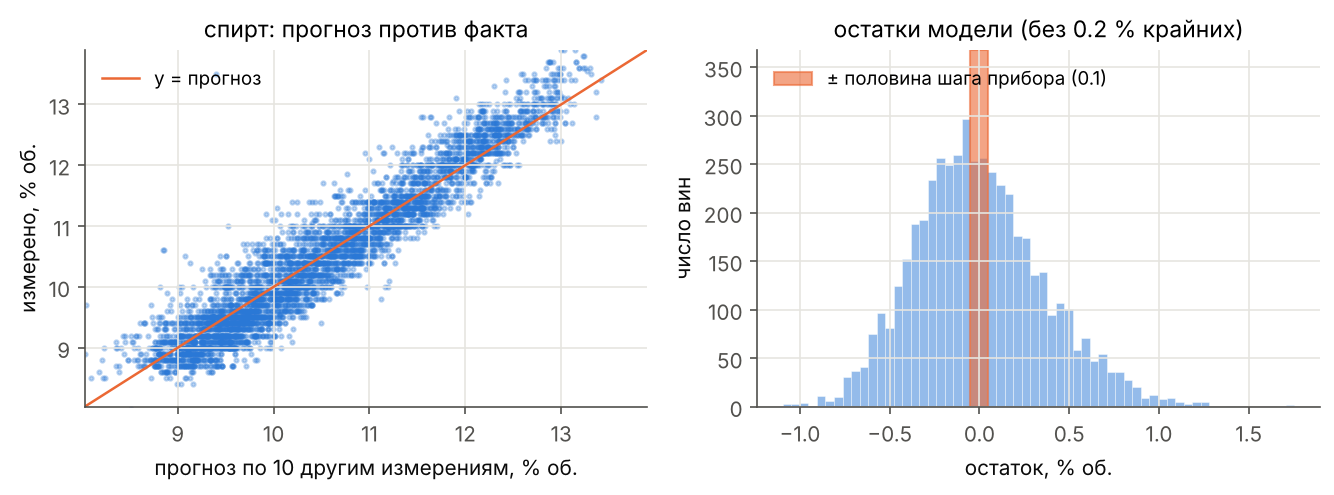

,nunique,min,max,count
0,2,11.6333,11.65,2
1,2,9.7333,9.75,2
2,2,10.1333,10.15,2
3,2,11.7333,11.75,2
4,2,10.9667,11.00,4


In [29]:
res_rv03 = stochastic.cv_r2_linear(X.drop(columns="alcohol"), X["alcohol"], k=5, seed=SEED)
knn_rv03 = {kk: stochastic.cv_r2_knn(X.drop(columns="alcohol"), X["alcohol"], k_neighbors=kk, k=5, seed=SEED) for kk in (5, 15, 30)}
twins_rv03 = stochastic.same_inputs_different_target(X, "alcohol")
print(f"Линейная модель: R² на кросс-валидации {res_rv03['r2_cv']:.3f}, СКО остатка {res_rv03['resid_std']:.4f} % об.")
for kk, r in knn_rv03.items():
    print(f"k ближайших соседей, k = {kk}: R² {r['r2_cv']:.3f}, СКО остатка {r['resid_std']:.4f} % об.")
print(f"Шаг записи прибора: 0.1 % об.; СКО самой величины: {X['alcohol'].std():.4f}")
print(f"Групп вин с одинаковыми остальными 10 измерениями, но разным значением: {len(twins_rv03)}")
plots.stochastic_panel(X["alcohol"].to_numpy(), res_rv03["resid"], "спирт", "% об.", 0.1, "rv03_stochastic.png");
twins_rv03.head()

<a id="fig16"></a>
*Рис. 16. Спирт: прогноз по 10 другим измерениям против измеренного значения (слева) и остатки модели в сравнении с шагом записи прибора (справа).*

**Результаты:**

- Линейная модель: $R^2$ 0.86, СКО остатка 0.46 % об. $k$ ближайших соседей: $R^2$ 0.79 / 0.77 / 0.75 при $k = 5 / 15 / 30$, СКО остатка 0.56–0.62.
- Шаг записи 0.1 % об., СКО самой величины 1.23.
- 10 групп вин с одинаковыми остальными измерениями и разным спиртом, разница в группах 0.017–0.03 % об. (например, 11.633 и 11.65), то есть меньше шага записи.
- На графике оси обрезаны по 0.1–99.9 % квантилям: есть единичная точка с прогнозом около −6 (вино с остаточным сахаром 65.8 г/дм³ и плотностью 1.039).

<a id="rv03-eda"></a>
### 4.2 EDA & Distribution

<sub>[↑ к содержанию](#toc)</sub>

In [30]:
x_rv03 = white["alcohol"].to_numpy()
out_rv03 = dsc.iqr_outliers(x_rv03)
print("Выбросов по правилу 1.5·IQR:", out_rv03.sum(), f"({out_rv03.mean():.1%})")
dsc.compare_table({"белые, все": x_rv03, "белые без дублей": white.drop_duplicates()["alcohol"], "красные": red["alcohol"]}).T

Выбросов по правилу 1.5·IQR: 0 (0.0%)


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
"белые, все",4898.0,10.5143,1.5144,1.2306,0.1170,8.0,9.5,10.4,11.4,14.2,1.9,9.4,0.4872,-0.6989,103.0,0.0067
белые без дублей,3961.0,10.5894,1.4813,1.2171,0.1149,8.0,9.5,10.4,11.4,14.2,1.9,9.5,0.4505,-0.6966,103.0,0.0067
красные,1599.0,10.4230,1.1356,1.0657,0.1022,8.4,9.5,10.2,11.1,14.9,1.6,9.5,0.8600,0.1957,65.0,0.0167


In [31]:
fit_rv03 = dist.fit_candidates(x_rv03)
fit_rv03

,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
skewnorm,3,-7559.6420,15125.2840,15144.7737,0.0569,"(9.9813, 8.8068, 2.1047)"
gamma,3,-7676.4188,15358.8376,15378.3273,0.0729,"(4.1217, 7.9482, 0.6226)"
weibull_min,3,-7693.8467,15393.6935,15413.1832,0.0757,"(2.1987, 7.9912, 2.859)"
lognorm,3,-7721.9037,15449.8074,15469.2971,0.0732,"(0.3986, 7.3413, 2.937)"
norm,2,-7965.8868,15935.7737,15948.7668,0.0916,"(10.5143, 1.2305)"


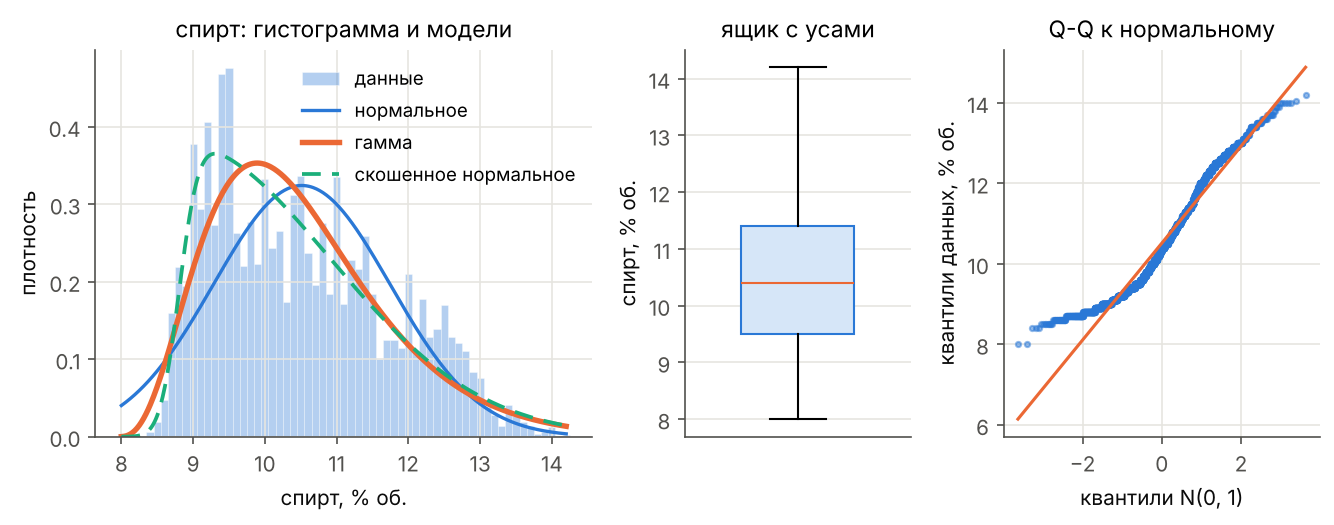

In [32]:
best_rv03 = {name: dist.fit(name, x_rv03) for name in ['norm', 'gamma', 'skewnorm']}
plots.eda_panel(x_rv03, "спирт", "% об.", best_rv03, "rv03_eda.png");

<a id="fig17"></a>
*Рис. 17. Спирт: гистограмма с подобранными плотностями, ящик с усами и Q-Q-график к нормальному распределению.*

**Результаты:**

- Среднее 10.51, медиана 10.4, мода 9.4 % об., СКО 1.23, КВ 12 %, диапазон 8.0–14.2.
- Асимметрия +0.49, эксцесс −0.70. Выбросов по $1.5\cdot\mathrm{IQR}$ нет.
- Гистограмма с зубцами: на значения вида 9.0, 9.5, 10.0 … приходится 25 % вин; при равномерной последней цифре было бы 20 %. Интервалы гистограммы выровнены по шагу 0.1.
- AIC: скошенная нормальная 15125, гамма 15359, Вейбулл 15394, логнормальная 15450, нормальная 15936. $D$ Колмогорова у всех ≥ 0.057.

<a id="rv03-math"></a>
#### 4.2.1 Математическое описание распределения

**Проверяемое семейство: гамма-распределение со сдвигом** [2, 4] $\Gamma(k, \theta, \text{loc})$. Справочные формулы:

$$f(x) = \frac{(x-\text{loc})^{k-1}\,e^{-(x-\text{loc})/\theta}}{\Gamma(k)\,\theta^{k}},\quad x > \text{loc}.$$

- Моменты: $E X = \text{loc} + k\theta$, $D X = k\theta^2$, асимметрия $2/\sqrt{k}$, избыточный эксцесс $6/k$.
- При целом $k$ это сумма $k$ независимых показательных величин (распределение Эрланга); при $k\to\infty$ стремится к нормальному.
- Носитель: $x > \text{loc}$.

**Почему проверялось гамма-распределение.** Для спирта взяли гамма-распределение со сдвигом, так как спирт всегда положительный и начинается не с 0, а примерно с 8 %. Гистограмма несимметричная, с хвостом вправо (асимметрия +0.49), поэтому мы искали модель с хвостом вправо, которая начинается не с нуля, как гамма со сдвигом. Но вершина у спирта плоская, эксцесс отрицательный (−0.70), а у гаммы эксцесс всегда положительный ($6/k > 0$), у скошенной нормальной тоже не меньше нуля. Именно плоская вершина мешает обеим моделям. Гистограмма спирта с зубцами: на круглые значения 9.0, 9.5, 10.0 приходится 25 % вин вместо ожидаемых 20 %, видимо, их часто записывали округлённо. Никакое распределение не подошло идеально: гамма отвергается ($p \approx 10^{-58}$), а лучшей по AIC становится скошенная нормальная (15125 против 15359 у гаммы и 15936 у нормальной), но и у неё расстояние Колмогорова до данных заметное ($D \ge 0.057$), а критерием согласия мы её не проверяли. Форма спирта сложнее простых формул. Для датчика есть выход: метод, которому формула не нужна, например квантильный, ведь он берёт значения прямо из данных.

<a id="rv03-indep"></a>
### 4.3 Independence & Estimations

<a id="rv03-dep"></a>
#### 4.3.1 Зависимость

Корреляции (Пирсон, Спирмен, Кендалл), хи-квадрат на таблице сопряжённости по квартилям и перестановочный тест.

<sub>[↑ к содержанию](#toc)</sub>

In [33]:
print("спирт и pH")
display(dependence.correlations(white["alcohol"], white["ph"]))
chi = dependence.chi2_independence(white["alcohol"], white["ph"], bins=4)
perm = dependence.permutation_spearman(white["alcohol"], white["ph"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

спирт и pH


,coef,p
method,,
pearson,0.1214,1.4901e-17
spearman,0.1489,1.1419e-25
kendall,0.1026,5.8500e-26


χ² = 236.1, df = 9, p = 8.37e-46, V Крамера = 0.127
перестановочный тест: ρ = 0.149, p = 0.0005, |ρ| при H0 не больше 0.044


ph,0,1,2,3
alcohol,,,,
0,535,394,321,186
1,191,336,255,355
2,311,261,291,327
3,277,255,289,314


In [34]:
print("спирт и фиксированная кислотность")
display(dependence.correlations(white["alcohol"], white["fixed_acidity"]))
chi = dependence.chi2_independence(white["alcohol"], white["fixed_acidity"], bins=4)
perm = dependence.permutation_spearman(white["alcohol"], white["fixed_acidity"], n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.2e}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}, |ρ| при H0 не больше {np.abs(perm['null']).max():.3f}")
chi["table"]

спирт и фиксированная кислотность


,coef,p
method,,
pearson,-0.1209,2.0854e-17
spearman,-0.1068,6.5824e-14
kendall,-0.0732,8.7284e-14


χ² = 94.6, df = 9, p = 1.98e-16, V Крамера = 0.080
перестановочный тест: ρ = -0.107, p = 0.0005, |ρ| при H0 не больше 0.051


fixed_acidity,0,1,2,3
alcohol,,,,
0,300,444,347,345
1,267,322,220,328
2,333,284,265,308
3,395,290,227,223


**Результаты:**

- **С pH:** $\rho = +0.15$, $V$ Крамера 0.13. **С кислотностью:** $\rho = -0.11$, $V$ Крамера 0.08. В обоих случаях $p < 10^{-13}$, $H_0$ о независимости отвергается.

<a id="rv03-cons"></a>
#### 4.3.2 Состоятельность оценок

Из совокупности берём выборки объёма $n$ с возвращением (1000 повторов на каждое $n$) и смотрим, как оценка приближается к значению параметра в совокупности.

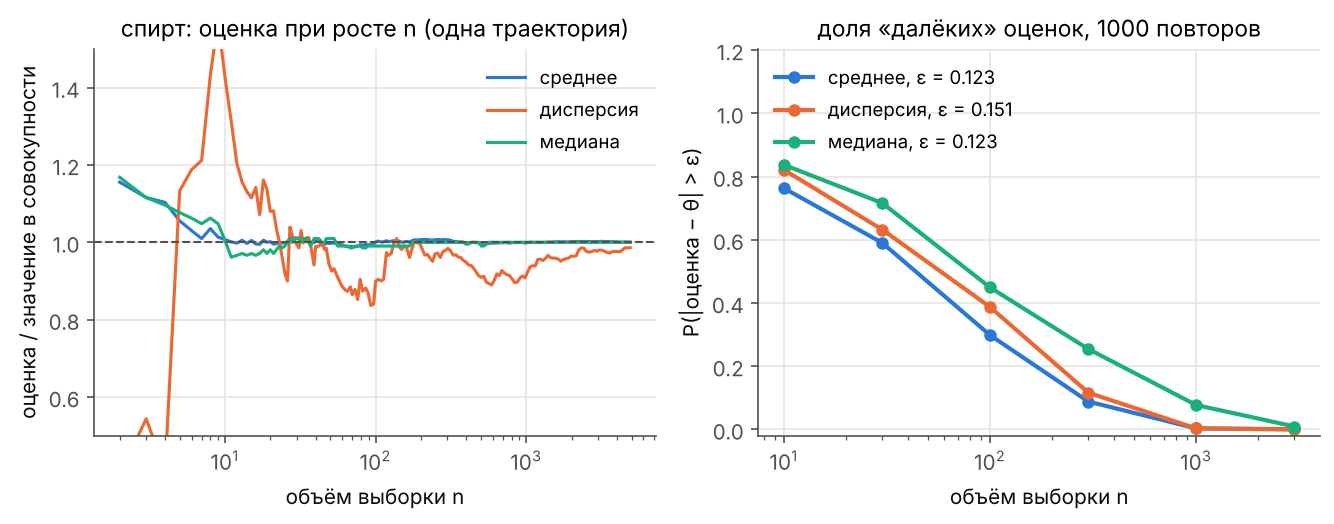

,оценка,n,theta,bias,sd_est,p_far,eps
0,mean,10,10.5143,2.7633e-03,0.3896,0.763,0.1230
1,mean,30,10.5143,-3.7214e-03,0.2245,0.590,0.1230
2,mean,100,10.5143,7.5319e-05,0.1197,0.298,0.1230
3,mean,300,10.5143,-1.8629e-03,0.0732,0.088,0.1230
4,mean,1000,10.5143,-2.0770e-03,0.0394,0.003,0.1230
5,mean,3000,10.5143,4.0594e-04,0.0220,0.000,0.1230
0,var,10,1.5141,3.1086e-03,0.5943,0.821,0.1514
1,var,30,1.5141,-8.8557e-03,0.3230,0.632,0.1514
2,var,100,1.5141,-2.5717e-03,0.1734,0.387,0.1514
3,var,300,1.5141,4.1169e-04,0.0988,0.116,0.1514


In [35]:
ns = [10, 30, 100, 300, 1000, 3000]
curves_rv03 = {e: estimation.consistency_curve(x_rv03, e, ns, reps=1000, seed=SEED) for e in ["mean", "var", "median"]}
running_rv03 = {e: estimation.running_estimate(x_rv03, e, n_max=4898, seed=SEED) for e in ["mean", "var", "median"]}
plots.consistency_panel(curves_rv03, running_rv03, "спирт", "rv03_consistency.png")
pd.concat(curves_rv03, names=["оценка"]).reset_index(level=0)[["оценка", "n", "theta", "bias", "sd_est", "p_far", "eps"]]

<a id="fig18"></a>
*Рис. 18. Спирт: траектория оценок при росте $n$ (слева) и доля оценок, отклонившихся от значения в совокупности больше чем на $\varepsilon$ (справа).*

**Результаты:**

- $\varepsilon = 0.123$ % об. для среднего и медианы, 0.151 для дисперсии.
- При $n = 10 \to 3000$: среднее 0.76 → 0.00, дисперсия 0.82 → 0.00, медиана 0.84 → 0.009.
- Смещение медианы от −0.03 до −0.06 при всех $n$; у среднего и дисперсии в пределах ±0.009.

<a id="rv03-norm"></a>
### 4.4 Normalization

<sub>[↑ к содержанию](#toc)</sub>

λ Бокса–Кокса = -1.481


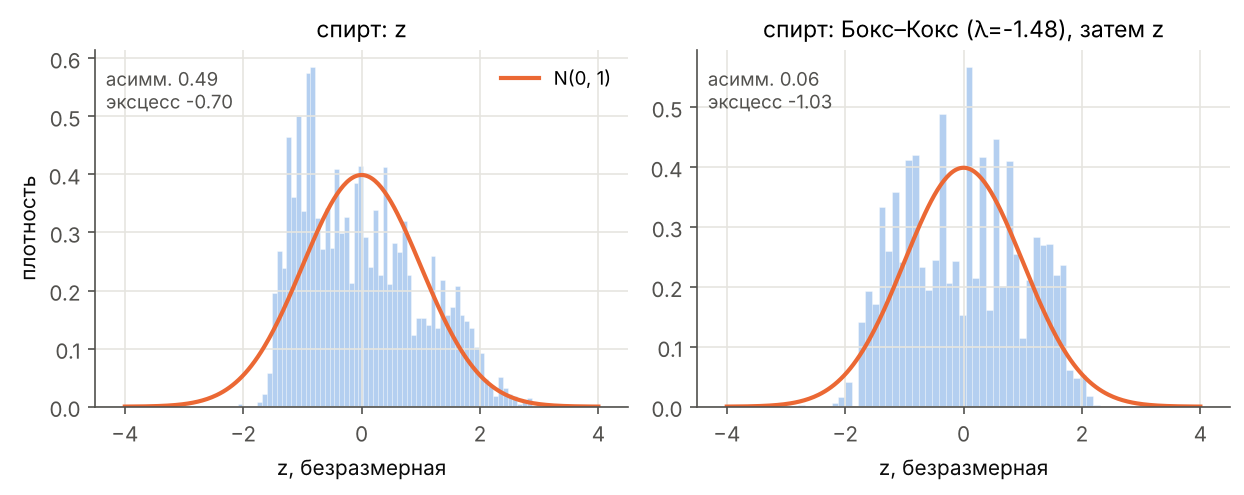

In [36]:
bc_alc, lam = normalize.boxcox(x_rv03)
print(f"λ Бокса–Кокса = {lam:.3f}")
plots.normalization_panel({"спирт: z": normalize.zscore(x_rv03), f"спирт: Бокс–Кокс (λ={lam:.2f}), затем z": normalize.zscore(bc_alc)},
                          "rv03_normalization.png");

<a id="fig19"></a>
*Рис. 19. Спирт: распределение после преобразования в сравнении с плотностью $N(0, 1)$.*

**Результаты:**

- $\lambda$ Бокса–Кокса $= -1.48$. После Бокса–Кокса и z: асимметрия 0.06, эксцесс −1.03 (до преобразования 0.49 и −0.70). Асимметрию преобразование убрало, но вершина стала ещё более плоской, поэтому нормальным спирт не стал.

<a id="rv03-sample"></a>
### 4.5 Sample vs Population

Одна выборка $n = 300$ (около 6 % совокупности) двумя способами, затем повторный эксперимент для разных $n$.

<sub>[↑ к содержанию](#toc)</sub>

КС выборка против совокупности: с возвращением p = 0.400, без возвращения p = 0.733
Повторов элементов в выборке с возвращением: 11


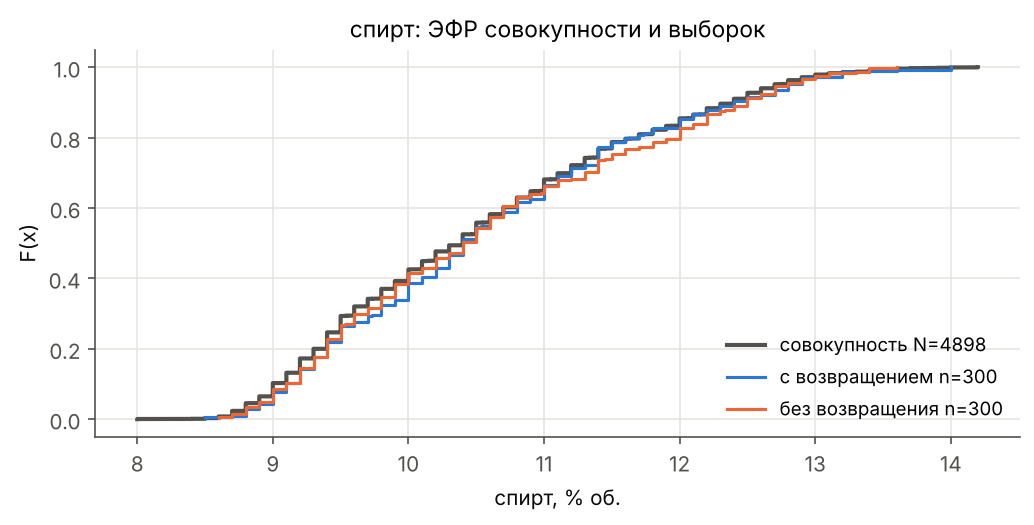

,n,mean,std,median,q25,q75,skew,kurt,ДИ 95% для среднего
совокупность,4898.0,10.5143,1.2306,10.4,9.5,11.4,0.4872,-0.6989,
с возвращением,300.0,10.5948,1.2184,10.4,9.5,11.4,0.5083,-0.5369,"[10.4564, 10.7333]"
без возвращения,300.0,10.5990,1.2511,10.4,9.5,11.5,0.4422,-0.8922,"[10.4612, 10.7367]"


In [37]:
n = 300
s_with_rv03 = sampling.draw(x_rv03, n, replace=True, seed=SEED)
s_without_rv03 = sampling.draw(x_rv03, n, replace=False, seed=SEED)
tab = dsc.compare_table({"совокупность": x_rv03, "с возвращением": s_with_rv03, "без возвращения": s_without_rv03}).T
tab["ДИ 95% для среднего"] = ["", np.round(sampling.ci_mean(s_with_rv03), 4), np.round(sampling.ci_mean(s_without_rv03, N=len(x_rv03)), 4)]
ks_w, ks_wo = stats.ks_2samp(s_with_rv03, x_rv03), stats.ks_2samp(s_without_rv03, x_rv03)
print(f"КС выборка против совокупности: с возвращением p = {ks_w.pvalue:.3f}, без возвращения p = {ks_wo.pvalue:.3f}")
print("Повторов элементов в выборке с возвращением:", n - len(np.unique(sampling.draw(np.arange(len(x_rv03)), n, True, SEED))))
plots.sampling_panel(x_rv03, s_with_rv03, s_without_rv03, "спирт", "% об.", "rv03_sampling.png")
tab[["n", "mean", "std", "median", "q25", "q75", "skew", "kurt", "ДИ 95% для среднего"]]

<a id="fig20"></a>
*Рис. 20. Спирт: эмпирические функции распределения совокупности и двух выборок $n = 300$.*

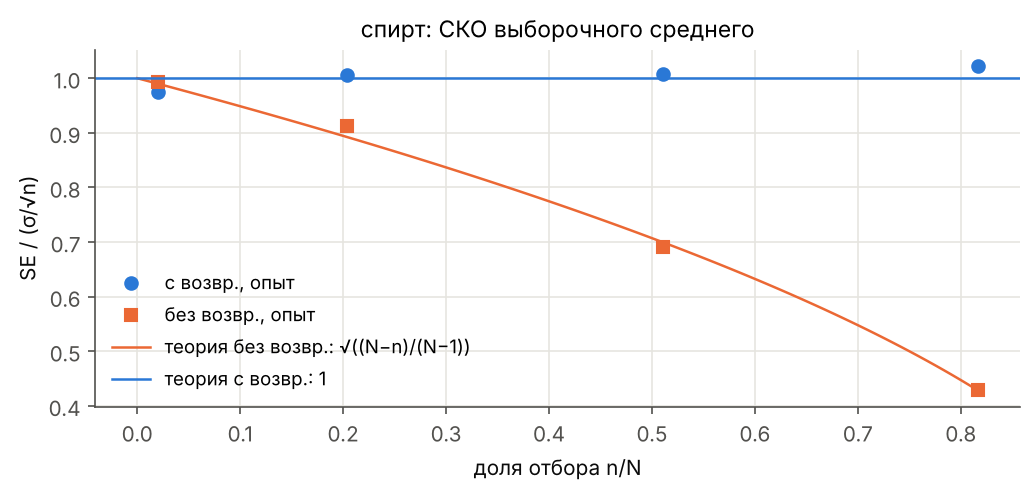

,n,n/N,se_with_emp,se_with_theory,se_without_emp,se_without_theory
0,100,0.0204,0.1199,0.1230,0.1221,0.1218
1,1000,0.2042,0.0391,0.0389,0.0355,0.0347
2,2500,0.5104,0.0248,0.0246,0.0170,0.0172
3,4000,0.8167,0.0199,0.0195,0.0083,0.0083


In [38]:
se_rv03 = sampling.se_mean_experiment(x_rv03, [100, 1000, 2500, 4000], reps=2000, seed=SEED)
plots.se_panel({"спирт": se_rv03}, "rv03_se.png")
se_rv03

<a id="fig21"></a>
*Рис. 21. Спирт: СКО выборочного среднего при отборе с возвращением и без, в долях $\sigma/\sqrt{n}$.*

**Результаты:**

- $n = 300$: среднее 10.59 и 10.60 при 10.51 в совокупности. 95 % ДИ [10.46; 10.73] и [10.46; 10.74], оба накрывают 10.51.
- КС $p = 0.40$ и 0.73. Квартили выборок отличаются от квартилей совокупности не больше чем на 0.1 % об.
- SE среднего без возвращения при $n = 4000$: 0.0083 против 0.0199; теория 0.0083.

<a id="rv03-hyp"></a>
### 4.6 Hypotheses

Уровень значимости $\alpha = 0.05$ для каждой проверки; поправка на множественность в [Lab resume](#resume).

<sub>[↑ к содержанию](#toc)</sub>

,test,H0,p,decision
0,"χ² Пирсона, 19 интервалов, df 15",X ~ гамма со сдвигом,4.2792e-58,отвергаем H0
1,Mann–Whitney (greater),P(A > B) ≤ 1/2,2.2173e-140,отвергаем H0


Хороших вин 1060, остальных 3838; средний спирт 11.42 против 10.27 % об.
Оценка P(спирт у хорошего > спирт у остального) = 0.752


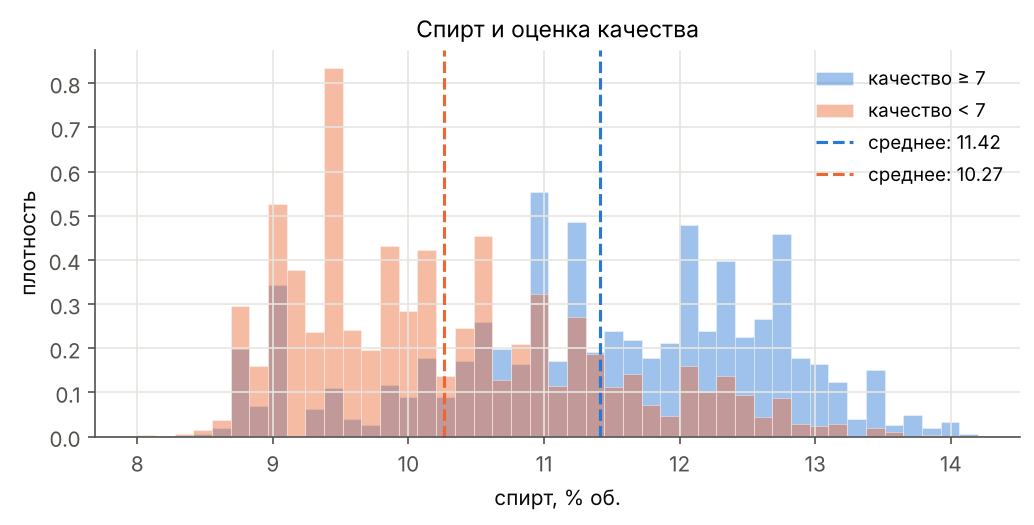

In [39]:
# H4: спирт распределён по гамма-закону со сдвигом
h4 = dist.chi2_gof(x_rv03, "gamma")
h4 |= {"test": f"χ² Пирсона, {h4['bins']} интервалов, df {h4['dof']}", "H0": "X ~ гамма со сдвигом"}
# H5: в хороших винах (качество ≥ 7) спирт не больше, чем в остальных: H0 P(A > B) ≤ 1/2
good, rest = white.alcohol[white.quality >= 7], white.alcohol[white.quality < 7]
h5 = hyp.mann_whitney(good, rest, alternative="greater")
h_rv03 = pd.DataFrame([h4, h5])[["test", "H0", "p", "decision"]]
display(h_rv03)
print(f"Хороших вин {len(good)}, остальных {len(rest)}; средний спирт {good.mean():.2f} против {rest.mean():.2f} % об.")
print(f"Оценка P(спирт у хорошего > спирт у остального) = {h5['p_a_gt_b']:.3f}")
plots.two_groups(good.to_numpy(), rest.to_numpy(), "качество ≥ 7", "качество < 7", "спирт, % об.",
                 "Спирт и оценка качества", "rv03_quality.png");

<a id="fig22"></a>
*Рис. 22. Содержание спирта в винах с оценкой качества $\ge 7$ и в остальных, пунктир: средние.*

**Результаты:**

- **H4 (гамма со сдвигом):** $\chi^2$ (19 интервалов, $\mathrm{df} = 15$) $p \approx 4\cdot 10^{-58}$. $H_0$ отвергается.
- **H5 ($H_0$: P(спирт у вина с качеством ≥ 7 > у остального) ≤ 1/2):** Манн–Уитни $p \approx 10^{-140}$, $H_0$ отвергается. Средний спирт 11.42 против 10.27 % об.; оценка $P(A > B) = 0.75.$

<a id="rv03-resume"></a>
### 4.7 Resume

<sub>[↑ к содержанию](#toc)</sub>

**Вывод по спирту.**

1. Спирт случайный, ведь он зависит от брожения и сахара в винограде. По другим измерениям, прежде всего по плотности, его можно предсказать хорошо ($R^2 = 0.86$), но не точно: ошибка в 5 раз больше шага прибора.
2. Спирт почти не связан с кислотностью и pH ($\rho = -0.11$ и $+0.15$), ведь он зависит от сахара и брожения, а кислотность и pH от другого. Эти связи значимые ($p < 10^{-13}$), но слабые: значимость говорит о том, равна связь нулю или нет, а сила о том, насколько она большая. Когда вин 4898, даже очень слабая связь оказывается значимой.
3. Ни одно распределение не подошло идеально: лучшим по AIC оказалось скошенное нормальное, а гамма-распределение отвергнуто. В основном мешают характеристики и особенности спирта, которые простые распределения не могут грамотно показать: плоская вершина и зубцы на гистограмме.
4. В хороших винах (оценка 7 и выше) спирта больше: 11.42 % против 10.27 %, и в 75 % пар «хорошее и обычное вино» в хорошем спирта больше. Но отсюда не следует, что вино хорошим делает спирт: мы только наблюдаем готовые вина, а не ставим опыт, и спирт может расти вместе с настоящей причиной, например со спелостью винограда. По этим данным видно только, что они встречаются вместе.
5. На результат повлияло то, как записаны данные. Почти все значения спирта записаны с шагом 0.1, но 69 значений записаны иначе, например 11.9333, а значения на ,0 и ,5 (9.0, 9.5, 10.0) встречаются чаще, чем должны, видимо, их округляли при записи. Это особенности записи данных, а не самого вина. Из-за них на гистограмме появились зубцы, и распределения совпадают с данными хуже, чем совпадали бы с настоящими значениями спирта.

<a id="resume"></a>
## 5. Lab resume

<a id="resume-metrics"></a>
### 5.1 Итоговые метрики

<sub>[↑ к содержанию](#toc)</sub>

In [40]:
summary = pd.DataFrame({
    "величина": ["pH", "фикс. кислотность", "спирт"],
    "единицы": ["ед. pH", "г/дм³", "% об."],
    "N": [len(x_rv01), len(x_rv02), len(x_rv03)],
    "среднее": [x.mean() for x in (x_rv01, x_rv02, x_rv03)],
    "СКО": [x.std(ddof=1) for x in (x_rv01, x_rv02, x_rv03)],
    "медиана": [np.median(x) for x in (x_rv01, x_rv02, x_rv03)],
    "асимметрия": [stats.skew(x) for x in (x_rv01, x_rv02, x_rv03)],
    "эксцесс": [stats.kurtosis(x) for x in (x_rv01, x_rv02, x_rv03)],
    "R² по 10 другим": [res_rv01["r2_cv"], res_rv02["r2_cv"], res_rv03["r2_cv"]],
    "проверяемое семейство": ["нормальное", "логнормальное", "гамма (сдвиг)"],
    "лучшая по AIC": [fit_rv01.index[0], fit_rv02.index[0], fit_rv03.index[0]],
}).set_index("величина")
summary

,единицы,N,среднее,СКО,медиана,асимметрия,эксцесс,R² по 10 другим,проверяемое семейство,лучшая по AIC
величина,,,,,,,,,,
pH,ед. pH,4898,3.1883,0.1510,3.18,0.4576,0.5290,0.5009,нормальное,skewnorm
фикс. кислотность,г/дм³,4898,6.8548,0.8439,6.80,0.6476,2.1687,0.5835,логнормальное,skewnorm
спирт,% об.,4898,10.5143,1.2306,10.40,0.4872,-0.6989,0.8609,гамма (сдвиг),skewnorm


<a id="resume-hyp"></a>
### 5.2 Все проверенные гипотезы и поправка Холма

<sub>[↑ к содержанию](#toc)</sub>

In [41]:
all_h = pd.DataFrame([
    {"гипотеза": "H1 pH ~ нормальное (K², все 4898)", "p": h_rv01.p.iloc[0]},
    {"гипотеза": "H1b pH ~ логнормальное со сдвигом (χ²)", "p": chi_lognorm_rv01["p"]},
    {"гипотеза": "H2 E[pH белых] = E[pH красных]", "p": h2["p"]},
    {"гипотеза": "H3 ln(кислотности) ~ нормальное (K²)", "p": h_rv02.p.iloc[0]},
    {"гипотеза": "H3b кислотность ~ логнормальное со сдвигом (χ²)", "p": chi_ln3_rv02["p"]},
    {"гипотеза": "H4 спирт ~ гамма", "p": h4["p"]},
    {"гипотеза": "H5 спирт в хороших винах не выше", "p": h5["p"]},
    {"гипотеза": "H6 pH и кислотность независимы (χ²)", "p": dependence.chi2_independence(white.ph, white.fixed_acidity)["p"]},
    {"гипотеза": "H7 pH и спирт независимы (χ²)", "p": dependence.chi2_independence(white.ph, white.alcohol)["p"]},
    {"гипотеза": "H8 кислотность и спирт независимы (χ²)", "p": dependence.chi2_independence(white.fixed_acidity, white.alcohol)["p"]},
])
all_h["отвергаем (α=0.05, Холм)"] = hyp.holm(all_h.p)
all_h

,гипотеза,p,"отвергаем (α=0.05, Холм)"
0,"H1 pH ~ нормальное (K², все 4898)",1.0892e-42,True
1,H1b pH ~ логнормальное со сдвигом (χ²),5.5549e-02,False
2,H2 E[pH белых] = E[pH красных],2.3423e-149,True
3,H3 ln(кислотности) ~ нормальное (K²),1.8880e-21,True
4,H3b кислотность ~ логнормальное со сдвигом (χ²),3.0871e-06,True
5,H4 спирт ~ гамма,4.2792e-58,True
6,H5 спирт в хороших винах не выше,2.2173e-140,True
7,H6 pH и кислотность независимы (χ²),1.1055e-164,True
8,H7 pH и спирт независимы (χ²),8.3748e-46,True
9,H8 кислотность и спирт независимы (χ²),1.9800e-16,True


<a id="resume-conclusions"></a>
### 5.3 Выводы по датасету

**Выводы по датасету.**

1. Все три величины, pH, кислотность и спирт, случайные: заранее, до измерения, их не узнать, а по другим измерениям их можно угадать только примерно ($R^2$ от 0.50 у pH до 0.86 у спирта).
2. pH и кислотность одной природы и зависимы: чем больше в вине кислот, тем ниже pH. Спирт другой природы, он зависит от сахара и брожения, с pH и кислотностью почти не связан, зато сильно связан с плотностью. В хороших винах спирта больше, но это не значит, что спирт делает вино хорошим.
3. pH у белых вин ниже, чем у красных, на 0.12, хотя кислот у красных больше. В литературе [8] это объясняют калием: при настаивании красного вина на кожице он переходит в вино и связывает часть кислот. Калия в датасете нет, поэтому для нас это только гипотеза.
4. Из 10 гипотез сводки 5.2 отвергнуты все, кроме одной: о том, что pH имеет логнормальное распределение со сдвигом. Причины разные. Гипотезы о форме распределения (H1, H3, H3b, H4) отвергаются потому, что при таком количестве вин заметны даже самые крошечные отличия от формулы, а на реальных данных такие отличия обычное дело. Остальные (H2, H5–H8) отвергнуты потому, что различия и связи действительно есть: белые и красные вина отличаются по pH, в хороших винах спирта больше, а pH, кислотность и спирт зависимы. Поэтому для датчика во втором спринте мы взяли pH: только для него модель не отвергнута, хотя и на грани ($p = 0.056$), а семейство выбирали после просмотра таблицы AIC.
5. У данных есть ограничения: 19 % вин — полные дубликаты, соседние вина в таблице очень схожи между собой, поэтому выборки пришлось брать случайно, а не подряд. Также есть особенности записи: шаг прибора, округление и странные значения спирта. Дубликаты почти не повлияли на результаты: без них средние меняются меньше чем на 0.08.
6. Размер выборки решает исход проверки: на 200 винах нормальность pH не отвергалась, а на 4898 отвергалась. Поэтому «не отвергнуто» на маленькой выборке не значит, что распределение подходит.
7. Оценки состоятельные: для всех трёх величин среднее, медиана и дисперсия приближаются к значению по всем винам с ростом выборки. Медленнее всех уточняется дисперсия кислотности: у неё самый тяжёлый хвост (эксцесс 2.17), и редкие крайние значения, в первую очередь 14.2, сильно меняют оценку.
8. По выборке можно судить обо всех винах: 300 вин из 4898 уже дают среднее, близкое к настоящему. Если отбирать без возвращения большую часть вин, ошибка меньше, чем по обычной формуле, и нужна поправка на конечность совокупности.

<a id="resume-lit"></a>
### 5.4 Литература и материалы

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // Decision Support Systems. 2009. Vol. 47, № 4. P. 547–553. DOI 10.1016/j.dss.2009.05.016. Данные: UCI Machine Learning Repository, Wine Quality, DOI 10.24432/C56S3T.
2. Лагутин М. Б. Наглядная математическая статистика. М.: БИНОМ. Лаборатория знаний (рекомендовано преподавателем).
3. Кнут Д. Э. Искусство программирования. Т. 2. Получисленные алгоритмы. 3-е изд. М.: Вильямс (рекомендовано преподавателем, понадобится в спринте 2).
4. Leemis L. M., McQueston J. T. Univariate Distribution Relationships // The American Statistician. 2008. Vol. 62, № 1. P. 45–53 (файл 2008amstat.pdf из #useful_links курса).
5. Cochran W. G. Sampling Techniques. 3rd ed. New York: Wiley, 1977 (поправка на конечность совокупности).
6. D'Agostino R., Pearson E. S. Tests for departure from normality // Biometrika. 1973. Vol. 60, № 3. P. 613–622.
7. Wald A., Wolfowitz J. On a test whether two samples are from the same population // Annals of Mathematical Statistics. 1940. Vol. 11, № 2. P. 147–162 (критерий серий).
8. Waterhouse A. L., Sacks G. L., Jeffery D. W. Understanding Wine Chemistry. Wiley, 2016 (химия кислот и pH вина).
9. Chernoff H., Lehmann E. L. The use of maximum likelihood estimates in $\chi^2$ tests for goodness of fit // Annals of Mathematical Statistics. 1954. Vol. 25, № 3. P. 579–586 (почему параметры для $\chi^2$ оцениваются по интервалам).
10. Lilliefors H. W. On the Kolmogorov–Smirnov test for normality with mean and variance unknown // Journal of the American Statistical Association. 1967. Vol. 62, № 318. P. 399–402 (КС с оценёнными параметрами).

11. Родопуло А. К. Основы биохимии виноделия. — 2-е изд., перераб. и доп. — М. : Лёгкая и пищевая промышленность, 1983. — 239 с. : ил. Гл. «Органические кислоты», «Брожение виноградного сусла», «Бактериальное брожение». *(найдено в каталоге РГБ, шифр ФВ Б 83-16/213)*
12. Валуйко Г. Г., Шольц-Куликов Е. П. Технология виноградных вин // Справочник по виноделию [Электронный ресурс]. URL: https://vinograd.info/knigi/spravochnik-po-vinodeliyu/tehnologiya-vinogradnyh-vin.html (дата обращения: 12.11.2026).

<a id="resume-marks"></a>
### 5.5 cat_mark_table

Критерии, которые, по нашему мнению, закрыты в спринте 1 (коэффициент выставляет преподаватель).

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| lab.ic.01.01 | [RV01](#rv01), [RV02](#rv02), [RV03](#rv03) | | три величины, для каждой обоснована стохастическая природа |
| lab.ic.01.02 | [2.3.1](#rv01-dep), [3.3.1](#rv02-dep), [4.3.1](#rv03-dep) | | pH и кислотность (одна природа): зависимы; спирт с ними слабо зависим |
| lab.ic.01.03 | [2.3.2](#rv01-cons), [3.3.2](#rv02-cons), [4.3.2](#rv03-cons) | | состоятельность среднего, дисперсии, медианы: P(отклонение > $\varepsilon$) → 0 |
| lab.ic.01.04 | [датасет](#dataset), [RV01](#rv01-eda), [RV02](#rv02-eda), [RV03](#rv03-eda) | | пропуски, дубли, округление, выбросы, сравнение с красными |
| lab.ic.01.05 | [RV01](#rv01-norm), [RV02](#rv02-norm), [RV03](#rv03-norm) | | стандартизация z, min-max, ln, Бокс–Кокс |
| lab.ic.01.06 | [RV01](#rv01-math), [RV02](#rv02-math), [RV03](#rv03-math) | | три разные формы: у pH логнормальное со сдвигом не отвергнуто (эксцесс +0.53), у кислотности тяжёлый правый хвост (эксцесс +2.17), у спирта плоская вершина (эксцесс −0.70), гамма и логнормальное для них отвергнуты; сравнение семейств по AIC в 5.1 |
| lab.ic.01.07 | [RV01 мат. описание](#rv01-math) | | нормальное распределение; обоснование выбора: ЦПТ, гистограмма, Q-Q, AIC, проверки |
| lab.ic.01.08 | [RV02](#rv02-math), [RV03](#rv03-math) | | логнормальное и гамма; обоснование выбора: область значений, форма гистограммы, логарифмирование, AIC, проверки |
| lab.ic.01.09 | [RV01](#rv01-sample), [RV02](#rv02-sample), [RV03](#rv03-sample) | | выборки с возвращением и без |
| lab.ic.01.10 | там же + Resume каждой величины | | выводы по каждой величине: [2.7](#rv01-resume), [3.7](#rv02-resume), [4.7](#rv03-resume); по датасету: [5.3](#resume-conclusions) |
| lab.ic.01.11 | [RV01 гипотезы](#rv01-hyp) | | H1 нормальность pH |
| lab.ic.01.12 | [RV01](#rv01-hyp), [RV02](#rv02-hyp), [RV03](#rv03-hyp), [сводка 5.2](#resume-hyp) | | H1b, H2, H3, H3b, H4–H8 |
| lab.ic.01.19 | [5.4](#resume-lit) | | ссылки на материалы |
| lab.ic.01.21 | [5.4](#resume-lit) | | Родопуло А. К. «Основы биохимии виноделия» найдена в каталоге РГБ (химия кислот и брожения) |
| lab.ic.01.24 | [5.1](#resume-metrics), [5.2](#resume-hyp) | | таблицы метрик и гипотез |
| КТвД: структура | [содержание](#toc) | | индексы разделов 1 → 1.1 → 1.1.1, якорь у каждого заголовка, «↑ к содержанию» |
| КТвД: скрытие кода | весь ноутбук | | код-ячейки свёрнуты (`source_hidden`, тег `hide-input` для HTML-экспорта) |
| КТвД: графики | [Рис. 1](#fig1)–[Рис. 22](#fig22) | | единый стиль `labstat.plots`, русские подписи, единицы на всех осях, нумерация и подписи рисунков |
| КТвД: формулы | весь ноутбук | | математика в тексте в LaTeX, единые обозначения ($H_0$, $p$, $\chi^2$, $\sigma/\sqrt{n}$) |
| КТвД: доп. задание | отдельный репозиторий | | датасет шрифтов, 2 случайные величины, EDA, датчик на marimo, сайт |

<sub>[↑ к содержанию](#toc)</sub>

# Lab01 - sprint 2

**Датчик случайных чисел на основе величины RV01 (pH).** Спринт 2 выполнила Быкова Кристина Денисовна
(ИСУ 501322, команда 27, трек КТвД): выбор величины и метода, мат. обоснование, код, тесты, выводы.

<a id="sp2"></a>
## 6. random 01 (датчик pH)

<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-desc"></a>
### 6.1 Description

Датчик выдаёт случайные значения pH белого вина. Значения подчиняются логнормальному распределению со сдвигом.
Нормальные числа получаем полярным методом (Марсальи), а для сравнения используем метод обратных функций.
Такой датчик позволяет получать сколько угодно «виртуальных» образцов вина без новых измерений, проверять
программы и модели на данных, похожих на настоящие, и проверить, правильно ли распределение pH описано формулой.

Почему pH: в спринте 1 гипотеза о логнормальном распределении со сдвигом для pH не отвергнута
($\chi^2$, $p = 0.056$, раздел [2.6](#rv01-hyp)), а для кислотности и спирта ни одно семейство не подошло.


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-math"></a>
### 6.2 math desc

**Распределение.** pH описываем логнормальным распределением со сдвигом:
$$\ln(X - \theta) \sim N(\mu, \sigma^2),$$
параметры из спринта 1 (метод максимального правдоподобия): $\theta = 2.088$, $\mu = \ln 1.0904 = 0.087$, $\sigma = 0.136$.

**От $Z$ к pH.** Датчик получает pH из стандартного нормального числа $Z \sim N(0, 1)$ в три шага:
$$X = \theta + e^{\mu + \sigma Z}.$$
Сначала $\mu + \sigma Z$: колокол сжимается (ведь $\sigma = 0.136 < 1$) и сдвигается, но остаётся нормальным. Затем экспонента делает все значения
положительными и сильнее растягивает большие, поэтому правый хвост вытягивается — получается логнормальное распределение.
В конце прибавляется сдвиг $\theta$: без него значения были бы около 1.09, а не около 3.18, как у pH.
Проверка: при $Z = 0$ получаем $2.088 + e^{0.087} = 3.178$ — это медиана данных (3.18).

**Полярный метод** [1, 2, 3]. Из двух равномерных чисел $U_1, U_2$:
$$V_1 = 2U_1 - 1,\quad V_2 = 2U_2 - 1,\quad S = V_1^2 + V_2^2.$$
Точки берутся только из круга ($0 < S < 1$). Из одной точки получаются два нормальных числа:
$$Z_{1,2} = V_{1,2}\sqrt{\frac{-2\ln S}{S}}.$$

**Почему получаются нормальные числа.** Чтобы получить пару нормальных чисел, нужно знать две вещи: случайное направление
и расстояние до центра. Расстояние тоже случайное: очень далёкие от центра точки должны попадаться редко, для этого есть формула
$\sqrt{-2\ln S}$. Точка в круге даёт случайное направление, так как в круге все стороны одинаковы, и точка с равной
вероятностью может уйти в любую сторону: везде есть место. А квадрат её расстояния до центра $S$ ведёт себя как случайное
число от 0 до 1, поэтому из него и получается расстояние по формуле. Весь квадрат брать нельзя, так как к углам
и диагоналям ведёт больше точек: в углах квадрата больше места, и точки чаще оказываются по диагоналям.

**То же формулами.** Точка $(V_1, V_2)$ равномерна в единичном круге, поэтому $P(S \le s) = \pi s / \pi = s$, то есть
$S \sim U(0, 1)$. В полярных координатах $V_1 = \sqrt{S}\cos\varphi$, $V_2 = \sqrt{S}\sin\varphi$, а плотность точки
в полярных координатах распадается на множитель от радиуса и множитель от угла, поэтому угол $\varphi \sim U(0, 2\pi)$ и не зависит от $S$.
Дальше $P(-2\ln S \le t) = P(S \ge e^{-t/2}) = 1 - e^{-t/2}$, то есть $R^2 = -2\ln S$ имеет показательное распределение со средним 2
(это $\chi^2$ с двумя степенями свободы). У пары $(R, \varphi)$ плотность $\frac{1}{2\pi}\,r\,e^{-r^2/2}$, а при переходе к $Z_1 = R\cos\varphi$, $Z_2 = R\sin\varphi$
элемент площади $dz_1\,dz_2 = r\,dr\,d\varphi$, поэтому $r$ сокращается и совместная плотность
$$f(z_1, z_2) = \frac{1}{2\pi}\,e^{-(z_1^2 + z_2^2)/2} = \phi(z_1)\,\phi(z_2),$$
она распалась на произведение двух плотностей $N(0, 1)$, значит $Z_1$ и $Z_2$ независимы и каждое стандартно нормально.
А так как $\cos\varphi = V_1/\sqrt{S}$, получаем $Z_1 = \sqrt{-2\ln S}\,V_1/\sqrt{S}$, это и есть формула выше.

Нормальные числа получаются через случайную точку на плоскости, как у Соболя в п. 3.2 «Применение полярных координат»
[3, с. 62–63]. Точки вне круга отбрасываются, то есть это метод отбора; по Соболю его эффективность равна вероятности того,
что точку не отбросят [3, с. 74]. У нас это площадь круга, делённая на площадь квадрата: $\pi/4 \approx 78.5\%$.

**Метод обратных функций** [3, 5]. У Соболя он назван «основным приемом моделирования случайных величин» [3, с. 44]:
если $U$ равномерно на $(0, 1)$, то $X = F^{-1}(U)$ имеет функцию распределения $F$ [3, теорема 2, с. 48].
Для нашего распределения $F^{-1}(U) = \theta + e^{\mu + \sigma\,\Phi^{-1}(U)}$, где $\Phi^{-1}$ — обратная функция стандартного
нормального распределения. При $U = 0.5$: $\Phi^{-1}(0.5) = 0$ и $X = 3.178$ — медиана.

**Почему метод даёт нужное распределение.** Функция $F$ модели непрерывна и строго растёт, поэтому $F^{-1}(U) \le x$
ровно тогда, когда $U \le F(x)$. Для равномерного $U$ вероятность этого равна самому $F(x)$:
$P(X \le x) = P(U \le F(x)) = F(x)$. То есть датчик выдаёт значения с функцией распределения модели. Например,
после округления до 0.01 значение «pH не больше 3.00» получается, когда датчик выдал меньше 3.005. По модели
$F(3.005) = 0.102$, то есть около 10.2 % значений; в данных таких вин 10.4 %. Датчик повторяет модель, а модель здесь
почти совпадает с данными.

**Сравнение методов.** Метод обратных функций универсальный и работает для любого распределения, а полярный даёт только
нормальные числа, зато обходится простыми операциями и выдаёт два числа за раз, хотя часть точек (вне круга) выбрасывает.

| | Полярный метод | Метод обратных функций |
|---|---|---|
| Равномерных чисел на одно значение | $2/(2\cdot\pi/4) \approx 1.27$ | 1 |
| Отбрасывает точки | да, около 21.5 % | нет |
| Сложные функции | только $\ln$, $\sqrt{\ }$ | $\Phi^{-1}$ без точной формулы |
| Чисел за один шаг | 2 | 1 |
| Подходит для | только нормального (дальше — формула $X = \theta + e^{\mu+\sigma Z}$) | любого распределения с известной $F^{-1}$ |


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-code"></a>
### 6.3 code

Код датчика лежит в модуле `ph_generator.py`, ниже его полный текст.

<sub>[↑ к содержанию](#toc)</sub>

In [42]:
import inspect
import ph_generator as gen
from labstat.plots import style, save, grid_bins, C1, C2, INK2
print(inspect.getsource(gen))

"""Датчик случайных значений pH белого вина (спринт 2).

Автор: Быкова К. Д. (ИСУ 501322).
pH ~ логнормальное со сдвигом: ln(X - theta) ~ N(mu, sigma^2).
Параметры подобраны в спринте 1 (scipy lognorm: s, loc, scale = 0.1363, 2.0877, 1.0904).
Основной метод: полярный метод Марсальи (N(0,1)) -> X = theta + exp(mu + sigma*Z).
Для сравнения: метод обратных функций X = theta + exp(mu + sigma * Phi^{-1}(U)).
"""
import numpy as np
from scipy import stats

sigma = 0.1363
theta = 2.0877
mu = np.log(1.0904)


def polar_normal(n, rng):
    """Полярный метод Марсальи: n чисел из N(0, 1) и доля принятых точек."""
    result, tried, accepted = [], 0, 0
    while len(result) < n:
        u1, u2 = rng.random(), rng.random()
        v1 = 2 * u1 - 1
        v2 = 2 * u2 - 1
        s = v1**2 + v2**2
        tried += 1
        if s > 0 and s < 1:
            accepted += 1
            factor = np.sqrt(-2 * np.log(s) / s)
            result.append(v1 * factor)
            result.append(v2 * factor)
    re

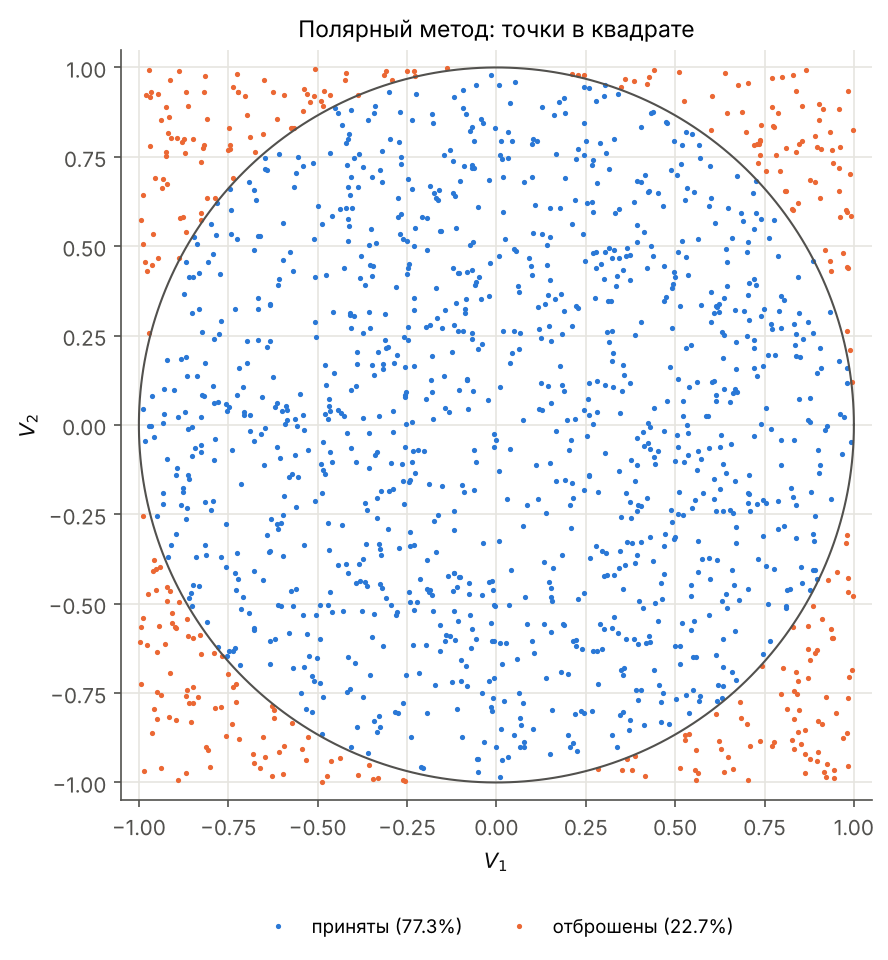

In [43]:
style()
r = np.random.default_rng(7)
v = 2 * r.random((1500, 2)) - 1
s_ = (v ** 2).sum(1)
inside = (s_ > 0) & (s_ < 1)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.plot(v[inside, 0], v[inside, 1], ".", ms=3, color=C1, label=f"приняты ({inside.mean():.1%})")
ax.plot(v[~inside, 0], v[~inside, 1], ".", ms=3, color=C2, label=f"отброшены ({(~inside).mean():.1%})")
t_ = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(t_), np.sin(t_), color=INK2, linewidth=1)
ax.set(xlabel="$V_1$", ylabel="$V_2$", title="Полярный метод: точки в квадрате", aspect="equal",
       xlim=(-1.05, 1.05), ylim=(-1.05, 1.05))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
save(fig, "sp2_polar.png");

<a id="fig23"></a>
*Рис. 23. Приняты точки внутри круга, их около 77 % (теоретически $\pi/4 \approx 78.5\%$), остальные отброшены. Отбираются точки с расстоянием до центра меньше единицы: так все направления равновероятны и колокол не перекашивается.*

<a id="sp2-tests"></a>
### 6.4 tests

**Сравнение метрик датчика и данных** (п. 3.1 задания). Датчиком получено столько же значений, сколько вин в данных ($N = 4898$),
`seed = 2026`. Значения датчика округляются до шага прибора 0.01.


<sub>[↑ к содержанию](#toc)</sub>

In [44]:
ph = white["ph"].to_numpy()
rng = np.random.default_rng(2026)
x_polar, acc_polar = gen.ph_polar(len(ph), rng)
x_inv = gen.ph_inverse(len(ph), rng)
z10k, acc10k = gen.polar_normal(10000, np.random.default_rng(2026))

def metrics(name, x):
    return {"": name, "среднее": x.mean(), "СКО": x.std(ddof=1), "медиана": np.median(x),
            "асимметрия": stats.skew(x), "эксцесс": stats.kurtosis(x), "мин": x.min(), "макс": x.max()}

sp2_metrics = pd.DataFrame([metrics("данные, 4898 вин", ph), metrics("датчик: полярный", np.round(x_polar, 2)),
                            metrics("датчик: обратные функции", np.round(x_inv, 2))]).set_index("").round(3)
display(sp2_metrics)
ks_tab = pd.DataFrame({
    "без округления": [stats.ks_2samp(x_polar, ph).pvalue, stats.ks_2samp(x_inv, ph).pvalue],
    "округление до 0.01": [stats.ks_2samp(np.round(x_polar, 2), ph).pvalue, stats.ks_2samp(np.round(x_inv, 2), ph).pvalue],
}, index=["полярный", "обратные функции"]).round(3)
print("p-значения двухвыборочного критерия Колмогорова–Смирнова (H0: датчик и данные из одного распределения):")
display(ks_tab)
print(f"Полярный метод, 10 000 нормальных чисел: среднее {z10k.mean():.4f}, СКО {z10k.std(ddof=1):.4f}, "
      f"доля принятых точек {acc10k:.4f} (теория pi/4 = {np.pi / 4:.4f}); "
      f"КС против N(0,1): p = {stats.kstest(z10k, 'norm').pvalue:.3f}")

,среднее,СКО,медиана,асимметрия,эксцесс,мин,макс
,,,,,,,
"данные, 4898 вин",3.188,0.151,3.18,0.458,0.529,2.72,3.82
датчик: полярный,3.189,0.150,3.18,0.427,0.430,2.77,3.93
датчик: обратные функции,3.188,0.151,3.18,0.448,0.277,2.76,3.90


p-значения двухвыборочного критерия Колмогорова–Смирнова (H0: датчик и данные из одного распределения):


,без округления,округление до 0.01
полярный,0.046,0.631
обратные функции,0.031,0.437


Полярный метод, 10 000 нормальных чисел: среднее -0.0083, СКО 0.9962, доля принятых точек 0.7872 (теория pi/4 = 0.7854); КС против N(0,1): p = 0.437


**Проверка на 300 запусках.** Один запуск даёт одно случайное значение $p$: при другом seed оно было бы другим.
Поэтому датчик запущен 300 раз с разными seed (каждый раз 4898 значений, округление до 0.01), и для каждого запуска
записаны $p$ критерия Колмогорова–Смирнова и эксцесс. Ориентир «около 5 % отказов при $\alpha = 0.05$» здесь не работает: данные во всех запусках одни и те же, а параметры модели подобраны по этим же данным, поэтому отказов ожидается меньше 5 %.

In [45]:
R = 300
runs = {"полярный": lambda r: gen.ph_polar(len(ph), r)[0], "обратные функции": lambda r: gen.ph_inverse(len(ph), r)}
rep = {}
for name, f in runs.items():
    p_vals, kurts = [], []
    for s_ in range(R):
        x_ = np.round(f(np.random.default_rng(10_000 + s_)), 2)
        p_vals.append(stats.ks_2samp(x_, ph).pvalue)
        kurts.append(stats.kurtosis(x_))
    p_vals, kurts = np.array(p_vals), np.array(kurts)
    rep[name] = {"доля запусков с p < 0.05": (p_vals < 0.05).mean(), "медиана p": np.median(p_vals),
                 "эксцесс: среднее": kurts.mean(), "эксцесс: 2.5 %": np.quantile(kurts, 0.025),
                 "эксцесс: 97.5 %": np.quantile(kurts, 0.975)}
rep_tab = pd.DataFrame(rep).T.round(3)
display(rep_tab)
w_ = np.exp(gen.sigma ** 2)
print(f"Эксцесс данных: {stats.kurtosis(ph):.3f}; теоретический эксцесс логнормальной модели: {w_**4 + 2*w_**3 + 3*w_**2 - 6:.3f}")

,доля запусков с p < 0.05,медиана p,эксцесс: среднее,эксцесс: 2.5 %,эксцесс: 97.5 %
полярный,0.04,0.437,0.309,0.101,0.594
обратные функции,0.02,0.394,0.298,0.101,0.551


Эксцесс данных: 0.529; теоретический эксцесс логнормальной модели: 0.305


**Что показала проверка на 300 запусках.** Результат одного запуска зависит от воли случая, и предугадать его нельзя,
поэтому мы запускаем датчик много раз: так появляется общая картина и статистика. Критерий отверг совпадение только
в 4 % запусков у полярного метода и в 2 % у метода обратных функций. Отказов мало: в большинстве запусков критерий не видит расхождения датчика с данными (медиана $p$ 0.437 и 0.394).
Точного ориентира для доли отказов у нас нет, поэтому это описание, а не доказательство совпадения.

**Эксцесс.** В одном запуске эксцесс датчика (0.43 и 0.28) отличается от эксцесса данных (0.53), и дело не только
в случайности. Датчик точно повторяет свою модель: средний эксцесс по запускам 0.309, у логнормальной модели
теоретически 0.305. Эксцесс данных 0.53 попадает в разброс датчика (в 95 % запусков от 0.10 до 0.59), но лежит у верхней границы.
Это согласуется с Q-Q-графиком (рис. 25): правый хвост у данных тяжелее, чем у модели.

**Автотесты** (`tests/test_ph_generator.py`, запуск `python -m pytest tests/test_ph_generator.py -v`): среднее полярного метода около 0, доля принятых точек около $\pi/4$, воспроизводимость при одинаковом seed, совпадение с данными по критерию КС; полярный метод даёт СКО около 1 и проходит критерий против $N(0, 1)$; метод обратных функций совпадает с данными; при $Z = 0$ датчик выдаёт медиану данных.

In [46]:
import subprocess, sys
out = subprocess.run([sys.executable, "-m", "pytest", "tests/test_ph_generator.py", "-v", "--no-header", "-p", "no:cacheprovider"],
                     capture_output=True, text=True)
print("\n".join(l for l in out.stdout.splitlines() if "PASSED" in l or "FAILED" in l or "passed" in l or "failed" in l))

tests/test_ph_generator.py::test_polar_mean PASSED                       [ 14%]
tests/test_ph_generator.py::test_acceptance PASSED                       [ 28%]
tests/test_ph_generator.py::test_seed PASSED                             [ 42%]
tests/test_ph_generator.py::test_like_data PASSED                        [ 57%]
tests/test_ph_generator.py::test_polar_is_standard_normal PASSED         [ 71%]
tests/test_ph_generator.py::test_inverse_like_data PASSED                [ 85%]
tests/test_ph_generator.py::test_median_at_zero PASSED                   [100%]
============================== 7 passed in 0.92s ===============================


**Скорость.** Время на 100 000 значений (лучшее из 3 замеров). В модуле `ph_generator.py` полярный метод перебирает точки
по одной в цикле Python; для честного сравнения рядом та же формула, записанная сразу для всех точек (векторно, средствами numpy).

In [47]:
import time

def polar_normal_vec(n, rng):
    """Полярный метод, все точки сразу: те же формулы, что в gen.polar_normal."""
    out = np.empty(0)
    while out.size < n:
        v = 2 * rng.random((n, 2)) - 1
        s = (v ** 2).sum(axis=1)
        ok = (s > 0) & (s < 1)
        v, s = v[ok], s[ok]
        out = np.concatenate([out, (v * np.sqrt(-2 * np.log(s) / s)[:, None]).ravel()])
    return out[:n]

def best_time(f, n=100_000, k=3):
    t = []
    for i in range(k):
        r = np.random.default_rng(i)
        t0 = time.perf_counter(); f(n, r); t.append(time.perf_counter() - t0)
    return min(t)

speed = pd.DataFrame({"время, мс": [best_time(lambda n, r: gen.polar_normal(n, r)) * 1e3,
                                    best_time(polar_normal_vec) * 1e3,
                                    best_time(lambda n, r: stats.norm.ppf(r.random(n))) * 1e3]},
                     index=["полярный (цикл, ph_generator.py)", "полярный (векторно)", "обратные функции"]).round(1)
z_vec = polar_normal_vec(20_000, np.random.default_rng(1))
display(speed)
print(f"Проверка векторной версии: среднее {z_vec.mean():.3f}, СКО {z_vec.std(ddof=1):.3f}, КС против N(0,1): p = {stats.kstest(z_vec, 'norm').pvalue:.2f}")

,"время, мс"
"полярный (цикл, ph_generator.py)",89.1
полярный (векторно),1.9
обратные функции,2.9


Проверка векторной версии: среднее -0.002, СКО 1.002, КС против N(0,1): p = 0.48


**Вывод о скорости.** Если бы полярный метод в моём коде обрабатывал не по одной точке, а все точки разом, он был бы
самым быстрым (1.9 мс против 2.9 мс у метода обратных функций). Но в моём коде точки перебираются по одной, поэтому
метод обратных функций работает быстрее (2.9 мс против 100 мс).

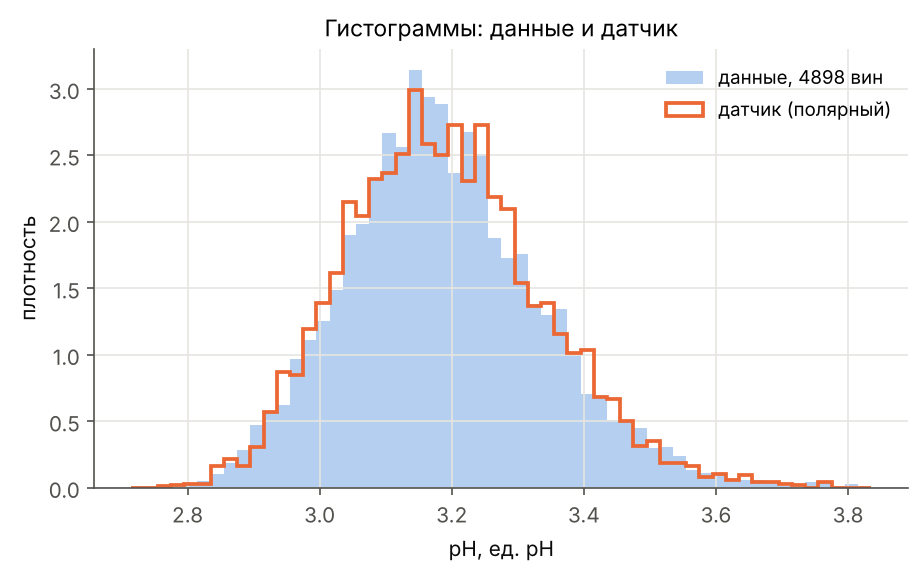

In [48]:
style()
xr = np.round(x_polar, 2)
fig, ax = plt.subplots(figsize=(7, 3.8))
b = grid_bins(ph)
ax.hist(ph, bins=b, density=True, color=C1, alpha=0.35, label="данные, 4898 вин")
ax.hist(xr, bins=b, density=True, histtype="step", color=C2, linewidth=1.8, label="датчик (полярный)")
ax.set(xlabel="pH, ед. pH", ylabel="плотность", title="Гистограммы: данные и датчик")
ax.legend()
save(fig, "sp2_hist.png");

<a id="fig24"></a>
*Рис. 24. Синий график показывает реальное распределение pH, оранжевая линия — значения, полученные датчиком. Формы почти совпадают: основная масса значений в центральной части, к краям их становится меньше.*

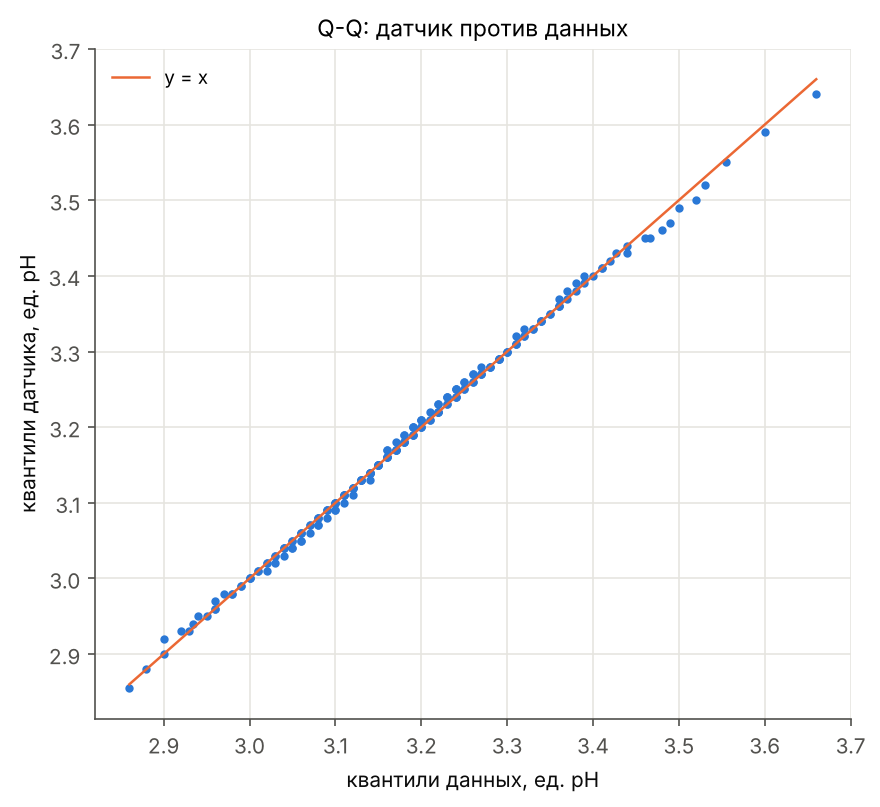

In [49]:
style()
p_ = np.linspace(0.005, 0.995, 199)
qd, qg = np.quantile(ph, p_), np.quantile(xr, p_)
fig, ax = plt.subplots(figsize=(6.5, 5.8))
ax.plot(qd, qg, "o", ms=3, color=C1)
ax.plot([qd[0], qd[-1]], [qd[0], qd[-1]], color=C2, linewidth=1.2, label="y = x")
ax.set(xlabel="квантили данных, ед. pH", ylabel="квантили датчика, ед. pH", title="Q-Q: датчик против данных")
ax.legend()
save(fig, "sp2_qq.png");

<a id="fig25"></a>
*Рис. 25. Точки на диагонали показывают, что значения датчика совпадают с распределением данных. На правом конце точки немного ниже прямой: в данных правый хвост длиннее, чем у модели, и самые высокие значения pH датчик выдаёт реже, чем они встречаются на самом деле.*

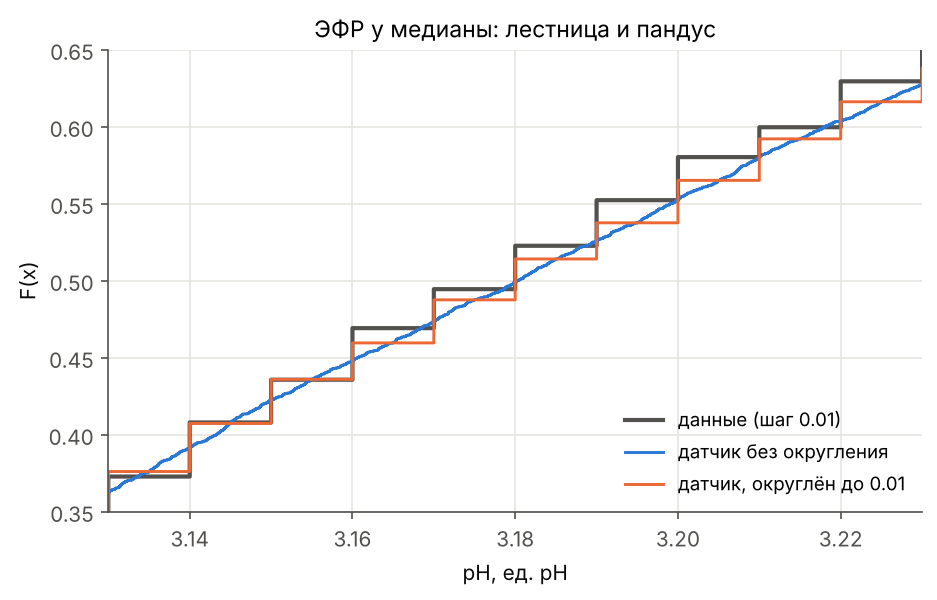

In [50]:
style()
fig, ax = plt.subplots(figsize=(7, 4))
for d_, col, lab, lw in ((ph, INK2, "данные (шаг 0.01)", 2), (x_polar, C1, "датчик без округления", 1.4),
                         (xr, C2, "датчик, округлён до 0.01", 1.4)):
    d_ = np.sort(d_)
    ax.step(d_, np.arange(1, d_.size + 1) / d_.size, where="post", color=col, linewidth=lw, label=lab)
ax.set(xlim=(3.13, 3.23), ylim=(0.35, 0.65), xlabel="pH, ед. pH", ylabel="F(x)", title="ЭФР у медианы: лестница и пандус")
ax.legend(loc="lower right")
save(fig, "sp2_ecdf.png");

<a id="fig26"></a>
*Рис. 26. Лестница показывает, что исходные данные записаны с шагом прибора 0.01, поэтому функция распределения прыгает ступенями. Пандус — неокруглённые значения датчика, они меняются плавно. После округления до 0.01 датчик тоже становится лестницей и почти совпадает с данными.*

<a id="sp2-resume"></a>
### 6.5 resume

1. Датчик получился: метрики сгенерированных значений почти совпадают с реальными данными — среднее 3.189 против 3.188,
   СКО 0.150 против 0.151, медиана 3.18 в обоих случаях.
2. Тесты подтвердили, что датчик работает правильно: доля принятых точек 0.787 совпадает с теоретической
   $\pi/4 \approx 0.785$, а критерий Колмогорова–Смирнова после округления не отвергает совпадение датчика с данными
   ($p = 0.63 > 0.05$). Это не доказывает совпадение, но расхождения критерий не видит.
3. Хуже всего датчик повторяет правый хвост: на Q-Q точки там отклоняются от прямой. У логнормальной модели хвост короче,
   чем у настоящих данных, поэтому значения из верхнего хвоста датчик выдаёт реже, чем они встречаются в данных. Отдельный максимум у него при этом может оказаться и больше (3.93 против 3.82 в таблице 8.1): это одно случайное значение.
4. Проверка с округлением показала, что датчик нужно приводить к точности прибора: данные записаны с шагом 0.01,
   и без такого же округления критерий находил различия, которых на самом деле нет ($p = 0.046$ без округления
   и $p = 0.63$ с округлением).
5. Метод обратных функций дал такой же результат, что и полярный: среднее 3.188, СКО 0.151, медиана 3.18, критерий
   Колмогорова–Смирнова не отвергает совпадение с данными ($p = 0.44$). В двух методах различается только способ
   получить $Z$, а формула перехода к pH одна, поэтому результаты совпадают в пределах случайного разброса.
6. Ограничение: числа формулы $\theta$, $\mu$, $\sigma$ подобраны на тех же винах, с которыми мы сравниваем датчик,
   а не на независимых, поэтому проверка получается немного в нашу пользу.


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-algo"></a>
## 7. Исследование алгоритмов датчиков

Любой датчик устроен в два шага: базовый датчик выдаёт равномерные числа от 0 до 1, а метод превращает их в нужное
распределение. Ниже 10 алгоритмов: 6 методов превращения и 4 базовых датчика. Код всех алгоритмов: пакет `labrng`
(`labrng/generators.py`), автотесты: `tests/test_labrng.py`.


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-algo-table"></a>
### 7.1 Сводная таблица

| Алгоритм | Тип | Распределение | Где применяется | Плюсы | Минусы |
|---|---|---|---|---|---|
| Полярный метод | метод | нормальное | Java `nextGaussian()`, шумы, ошибки измерений | простые операции, два числа за раз, быстрый | выбрасывает около 21.5 % точек |
| Метод обратных функций | метод | любое с известной $F^{-1}$ | показательное распределение, сравнение моделей | одно число на значение, ничего не выбрасывает | для многих распределений $F^{-1}$ без точной формулы |
| Бокс–Мюллер | метод | нормальное | NVIDIA cuRAND на видеокартах | ничего не выбрасывает | нужны синус и косинус |
| Метод отношений | метод | многие (у нас нормальное) | генерация нестандартных распределений | почти универсальный, простые операции | выбрасывает около 27 % точек |
| Метод Неймана | метод | любое, даже без формулы | распределения, заданные гистограммой | работает для любой формы | при узкой высокой «горке» выбрасывает почти все точки |
| Квантильное преобразование | метод | как в данных | когда ни одна формула не подходит | не нужна модель, повторяет данные | не выходит за min и max данных |
| RANDU | базовый | равномерное | IBM, 1960-е | одно умножение, очень быстрый | тройки лежат на 15 плоскостях |
| ЛКГ (MMIX) | базовый | равномерное | `java.util.Random`, игры | быстрый, мало памяти | скрытые плоскости, предсказуем |
| Вихрь Мерсенна | базовый | равномерное | Python `random`, Excel, MATLAB, R | период $2^{19937}-1$, нет плоскостей | 2.5 КБ памяти, не проходит строгие тесты |
| PCG64 | базовый | равномерное | numpy по умолчанию (и наш датчик pH) | проходит строгие тесты, мало памяти, потоки | молодой, не для шифрования |


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-algo-methods"></a>
### 7.2 Методы превращения равномерных чисел в распределение

**1. Полярный метод (Марсальи).**

*Что это и какое распределение даёт.* Полярный метод придумали Джордж Марсалья и Томас Брэй в 1964 году как улучшение метода Бокса–Мюллера. Он превращает равномерные случайные числа в нормальные, то есть даёт стандартное нормальное распределение $N(0, 1)$, тот самый «колокол». Сам по себе метод другие распределения не даёт, но из нормального числа можно получить многие другие с помощью формулы. Так мы и сделали для pH: $X = \theta + e^{\mu + \sigma Z}$ превращает колокол в логнормальное распределение со сдвигом.

*Как работает.* Бросаем точку в квадрат и оставляем её, только если она попала в круг. В круге все стороны одинаковы, поэтому направление точки получается случайным, а по её расстоянию до центра формула $\sqrt{-2\ln S}$ задаёт, насколько далеко отклонить число. Из одной такой точки получаются сразу два нормальных числа.

*Где применяется.* Полярный метод встроен в язык Java: стандартная функция `nextGaussian()` выдаёт нормальные числа именно им [13]. Нормальные числа нужны везде, где моделируют случайные отклонения: шумы в сигналах, ошибки измерений, колебания цен в финансовых моделях. Ещё метод служит первым шагом для других распределений, как в нашем датчике pH.

*Сильные стороны.* Метод обходится простыми операциями, логарифмом и квадратным корнем, без сложных функций, у которых нет точной формулы. Из одной точки получается сразу два числа. Если обрабатывать все точки разом, он очень быстрый: в нашем замере 1.9 мс на 100 000 чисел, быстрее метода обратных функций (2.9 мс).

*Слабые стороны.* Часть точек пропадает зря: всё, что попало в углы квадрата вне круга, выбрасывается. Это около 21.5 %, поэтому на одно нормальное число в среднем тратится 1.27 случайных. Количество попыток заранее неизвестно, оно зависит от случая. И сам по себе метод даёт только нормальное распределение, для любого другого нужна ещё своя формула.

*Ссылки:* [2], [3, с. 62–63], [1, § 3.4.1]. *Пример:* датчик pH, раздел [6](#sp2); таблица в [7.4](#sp2-algo-ph).

**2. Метод обратных функций.**

*Что это и какое распределение даёт.* Это самый универсальный способ: им можно получить практически любое распределение, надо лишь поменять формулу. У Соболя он назван «основным приемом моделирования случайных величин». Метод берёт одно случайное число $U$ от 0 до 1, это место в очереди, и выдаёт значение, которое стоит на этом месте: $X = F^{-1}(U)$.

*Где применяется.* Им получают, например, показательное распределение, которым описывают время до поломки прибора или время между звонками в колл-центр; там формула совсем простая: $X = -\ln(U)/\lambda$. Метод используют и тогда, когда нужно сравнить два варианта модели на одних и тех же случайных числах.

*Сильные стороны.* На одно значение тратится одно случайное число: позиция в очереди сразу даёт результат. Метод ничего не выбрасывает, поэтому мы не тратим числа зря. Маленькое $U$ даёт маленькое значение, а большое даёт большое, потому что значения выстроены по порядку, от маленького к большому. Поэтому метод удобен для сравнения моделей на одних и тех же числах.

*Слабые стороны.* Нужно знать обратную функцию $F^{-1}$, а для многих распределений точной формулы у неё нет. Например, для нормального $\Phi^{-1}$ компьютер считает приближённо, и это медленнее простых операций: в нашем замере 2.9 мс против 1.9 мс у полярного метода.

*Ссылки:* [3, с. 44–48, теорема 2 на с. 48], [5, с. 58]. *Пример:* датчик pH, раздел [6](#sp2).

**3. Метод Бокса–Мюллера.**

*Что это и какое распределение даёт.* Метод придумали Джордж Бокс и Мервин Мюллер в 1958 году. Он даёт нормальное распределение $N(0, 1)$. Направление и расстояние до центра берутся прямо из двух равномерных чисел: угол $2\pi U_2$ и расстояние $\sqrt{-2\ln U_1}$. Из двух равномерных чисел получаются два нормальных:
$$Z_1 = \sqrt{-2\ln U_1}\cos(2\pi U_2),\qquad Z_2 = \sqrt{-2\ln U_1}\sin(2\pi U_2).$$

*Где применяется.* Например, в библиотеке NVIDIA cuRAND для случайных чисел на видеокартах. Там важно, что метод ничего не выбрасывает: тысячи потоков считают одновременно и должны делать одинаковое число шагов.

*Сильные стороны.* Ничего не выбрасывается, никакие значения не теряются: каждые два случайных числа сразу дают два нормальных, и заранее известно, сколько чисел понадобится.

*Слабые стороны.* По сравнению с полярным методом вычисления сложнее, ведь здесь нужны ещё синус и косинус. Полярный метод придумали как раз чтобы обойтись без них.

*Ссылки:* [6], [12]. *Пример:* таблица в [7.4](#sp2-algo-ph).

**4. Метод отношений (Киндермана–Монахана).**

*Что это и какое распределение даёт.* Метод придумали Киндерман и Монахан в 1977 году. Точка $(u, v)$ бросается в прямоугольник, и берётся отношение $x = v/u$; точка остаётся, только если попала в особую фигуру. Метод может дать разные распределения, нужно просто менять и выводить форму фигуры для каждого из них. В нашем коде он даёт нормальное распределение: точка принимается при $x^2 \le -4\ln u$.

*Где применяется.* В библиотеке GSL этим методом сделан один из нормальных датчиков (`gsl_ran_gaussian_ratio_method`), ещё им получают гамма- и t-распределения [7].

*Сильные стороны.* Метод почти универсальный: один и тот же приём подходит для многих распределений. Он содержит в себе простые операции, деление и логарифм, без синуса и косинуса.

*Слабые стороны.* Он тоже выбрасывает точки, и даже больше, чем полярный: около 27 % против 21.5 %. Поэтому на одно число тратится больше случайных. Для каждого нового распределения форму фигуры приходится выводить заново.

*Ссылки:* [8], [7]. *Пример:* таблица в [7.4](#sp2-algo-ph).

**5. Метод Неймана (метод отбора).**

*Что это и какое распределение даёт.* Метод придумал Джон фон Нейман в 1951 году. Он может дать любое распределение. Рисуем «горку», то есть график плотности, обводим её прямоугольником и бросаем туда случайные точки. Если точка попала под горку, оставляем её координату $x$, если над горкой, выбрасываем. Там, где горка выше, значений получается больше.

*Где применяется.* Когда у распределения нет удобной формулы, например если оно задано гистограммой данных. Так сделано в нашем коде: «горка» строится по гистограмме pH.

*Сильные стороны.* Работает для любой формы, даже если формулы нет: всего лишь нужно взять гистограмму и знать её значения.

*Слабые стороны.* Если горка узкая и высокая, под неё попадёт очень мало точек, и большинство будет выброшено: для pH принимается меньше трети точек (таблица в [7.4](#sp2-algo-ph)). Ещё нужно знать границы значений и самую высокую точку горки, поэтому длинные хвосты приходится обрезать.

*Ссылки:* [9], [3, с. 74–76]. *Пример:* таблица в [7.4](#sp2-algo-ph).

**6. Квантильное преобразование.**

*Что это и какое распределение даёт.* Это родственник метода обратных функций. Он тоже берёт случайное место в очереди $U$, но отличается тем, что находит значение прямо из реальных данных, а не по формуле распределения: наблюдения выстраиваются по возрастанию, и берётся значение на месте $U$ (между соседними наблюдениями берётся промежуточное). Поэтому он даёт то распределение, которое есть в данных.

*Где применяется.* Когда ни одна формула не подходит к данным, а нужно получить похожие значения. Для кислотности и спирта в спринте 1 ни одно семейство не подошло, и это был бы самый простой путь к датчику для них.

*Сильные стороны.* Не нужна никакая формула и модель, так как ничего нового по сути датчик не выводит: он повторяет данные почти точно.

*Слабые стороны.* Значения ограничены реальными данными, то есть минимальным и максимальным наблюдением: значений за этими границами датчик не выдаст никогда. И он повторяет все особенности конкретной выборки, даже случайные.

*Ссылки:* [3, с. 44–48] (тот же принцип, что у метода обратных функций). *Пример:* таблица в [7.4](#sp2-algo-ph).


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-algo-bases"></a>
### 7.3 Базовые датчики равномерных чисел

**7. RANDU (базовый датчик IBM).**

*Что это и какое распределение даёт.* В отличие от методов выше, RANDU создаёт сами исходные случайные числа, равномерные от 0 до 1. Каждое новое число строится по формуле на базе предыдущего: $x_{k+1} = 65539 \cdot x_k \bmod 2^{31}$, а потом делится на $2^{31}$. Такие датчики называются линейными конгруэнтными. Их числа на самом деле не случайные, а псевдослучайные: они только выглядят случайными.

*Где применялся.* RANDU появился у IBM в 1960-х и долго был стандартным датчиком на их компьютерах, на нём сделано много научных расчётов того времени.

*Сильные стороны.* Производится очень простое действие, одно умножение и остаток от деления, поэтому датчик очень быстрый.

*Слабые стороны.* Если брать числа тройками и ставить их как точки в кубе, у хорошего датчика куб был бы заполнен равномерно, а у RANDU все точки выстраиваются только на 15 плоскостях, а между ними пусто. Причина в числе $65539 = 2^{16} + 3$: из-за него каждое число связано с двумя предыдущими формулой $x_{k+2} = 6x_{k+1} - 9x_k \pmod{2^{31}}$. Поэтому пользоваться этим датчиком сейчас очень рискованно: многие старые расчёты на нём даже пришлось перепроверять.

*Ссылки:* [1, § 3.3.4]. *Пример:* рис. 27 в [7.5](#sp2-algo-triples).

**8. ЛКГ с хорошими параметрами (MMIX).**

*Что это и какое распределение даёт.* Это тот же тип датчика, что RANDU, линейный конгруэнтный: $x_{k+1} = (a\,x_k + c) \bmod 2^{64}$. Он даёт равномерные числа от 0 до 1. Отличие в том, что в RANDU взяты неудачные числа, а в MMIX новые удобные, которые выбрал Кнут: $a = 6364136223846793005$, $c = 1442695040888963407$.

*Где применяется.* Это самый распространённый тип датчика в истории: например, `java.util.Random` в Java тоже ЛКГ. Им пользуются, когда нужна скорость, а особая надёжность не нужна: в играх и простых симуляциях.

*Сильные стороны.* Он такой же быстрый и простой, как RANDU, и почти не занимает памяти: хранит только одно число.

*Слабые стороны.* Точки всё равно ложатся в плоскости, может быть не так заметно, как у RANDU, но всё равно. Ещё по нескольким числам можно угадать все следующие, поэтому для паролей и шифрования он не годится.

*Ссылки:* [1, § 3.2.1, § 3.3.4]. *Пример:* рис. 27 в [7.5](#sp2-algo-triples).

**9. Вихрь Мерсенна (Mersenne Twister).**

*Что это и какое распределение даёт.* Датчик придумали Макото Мацумото и Такудзи Нисимура в 1998 году. Он даёт равномерные числа от 0 до 1. В отличие от ЛКГ, он хранит не одно число, а сразу 624 и каждый раз перемешивает их.

*Где применяется.* Он применяется в модуле `random` языка Python а ещё в Excel, MATLAB и R; в numpy он был датчиком по умолчанию до появления PCG64.

*Сильные стороны.* Он имеет огромный период: $2^{19937} - 1$ чисел до первого повтора, это число из 6000 цифр. И у него нет таких плоскостей, как у RANDU: числа равномерны даже в 623-мерном пространстве.

*Слабые стороны.* Из-за огромного объёма чисел он занимает много памяти: около 2.5 КБ против одного числа у ЛКГ. Ещё по 624 его числам подряд можно предсказать все следующие, а самые строгие современные тесты на случайность он не проходит, поэтому его вытесняют более новые датчики.

*Ссылки:* [10]. *Пример:* рис. 27 в [7.5](#sp2-algo-triples).

**10. PCG64.**

*Что это и какое распределение даёт.* Датчик придумала Мелисса О'Нил в 2014 году. Он даёт равномерные числа от 0 до 1. Внутри этого алгоритма встроен обычный ЛКГ, который быстрый и простой. Но перед выдачей числа датчик перемешивает его биты и сдвигает их, и тем самым составляет итоговое число. Это прячет скрытую структуру с плоскостями, которая есть у любого ЛКГ.

*Где применяется.* Это стандартный датчик numpy с 2019 года: функция `np.random.default_rng()` по умолчанию использует PCG64. На нём работает и наш датчик pH в разделе 6.

*Сильные стороны.* Он проходит самые строгие современные тесты на случайность, быстрый и использует мало памяти: 32 байта против 2.5 КБ у вихря Мерсенна. Можно сделать много независимых потоков чисел для параллельных расчётов.

*Слабые стороны.* Он молодой и изучен меньше, чем старые датчики. И, как все обычные датчики, он не годится для шифрования и паролей: для этого нужны специальные криптографические датчики.

*Ссылки:* [11]. *Пример:* датчик pH, раздел [6](#sp2); рис. 27 в [7.5](#sp2-algo-triples).


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-algo-ph"></a>
### 7.4 Пример: все шесть методов на pH

Каждый метод выдаёт 4898 значений pH (базовый датчик PCG64, округление до 0.01). Методы «через модель» используют ту же
логнормальную модель со сдвигом, что и раздел 6. Для каждого метода: $p$ критерия Колмогорова–Смирнова при одном запуске,
доля запусков с $p < 0.05$ из 100, доля принятых точек и время.

Числа здесь отличаются от раздела 6, например $p$ у полярного метода при том же seed. Причина в другой реализации:
пакет `labrng` сам подбирает параметры модели по данным и расходует случайные числа в другом порядке. Квантильное
преобразование проходит проверку заведомо, ведь оно берёт значения из тех же данных, с которыми сравнивается.


<sub>[↑ к содержанию](#toc)</sub>

In [51]:
from labrng import generators as G
import time
rows_ = []
for m_ in G.METHODS:
    t0 = time.perf_counter()
    x_, info_ = G.generate(ph, len(ph), method=m_, family="lognorm", base="pcg64", seed=2026, step=0.01)
    dt_ = (time.perf_counter() - t0) * 1e3
    rej_ = np.mean([stats.ks_2samp(G.generate(ph, len(ph), method=m_, family="lognorm", base="pcg64",
                                              seed=20_000 + k, step=0.01)[0], ph).pvalue < 0.05 for k in range(100)])
    rows_.append({"метод": G.METHOD_RU[m_], "КС p (seed 2026)": stats.ks_2samp(x_, ph).pvalue,
                  "доля запусков с p < 0.05": rej_, "доля принятых точек": info_["accept"], "время, мс": dt_})
algo_tab = pd.DataFrame(rows_).set_index("метод").round(3)
algo_tab

,КС p (seed 2026),доля запусков с p < 0.05,доля принятых точек,"время, мс"
метод,,,,
Квантильное преобразование (эмпирическая F⁻¹),0.927,0.00,1.000,0.735
Метод обратной функции по модели,0.367,0.02,1.000,1.628
Бокс–Мюллер → модель,0.367,0.01,1.000,1.909
Полярный метод Марсальи → модель,0.304,0.03,0.787,1.323
Метод отношений (Киндерман–Монахан) → модель,0.797,0.04,0.729,1.403
Метод Неймана (отбор) по гистограмме,0.547,0.07,0.291,1.209


<a id="sp2-algo-triples"></a>
### 7.5 Пример: тройки чисел у базовых датчиков

Для каждого базового датчика взяты 3000 троек подряд идущих чисел $(u_k, u_{k+1}, u_{k+2})$ и показаны в проекции
$(6u_{k+1} - 9u_k) \bmod 1$ по горизонтали и $u_{k+2}$ по вертикали. Для RANDU эта проекция выбрана по его формуле
$x_{k+2} = 6x_{k+1} - 9x_k$: если связь есть, точки лягут на прямую.


<sub>[↑ к содержанию](#toc)</sub>

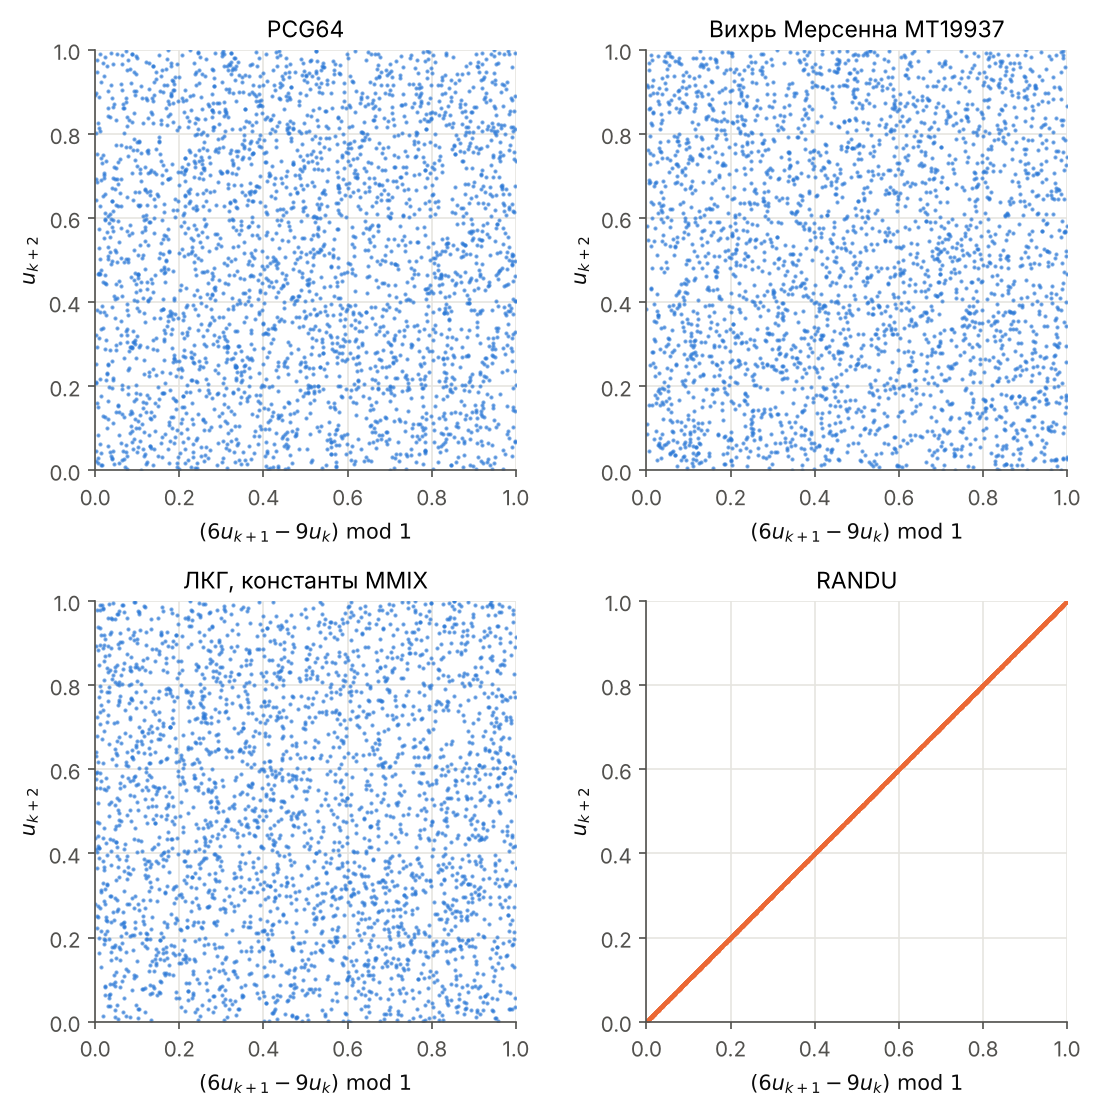

In [52]:
style()
fig, axs = plt.subplots(2, 2, figsize=(7.5, 7.5))
for a_, b_ in zip(axs.ravel(), G.BASES):
    u_ = G.Uniform(b_, 7)(3002)
    a_.plot((6 * u_[1:-1] - 9 * u_[:-2]) % 1.0, u_[2:], ".", ms=2, color=C2 if b_ == "randu" else C1, alpha=0.6)
    a_.set(title=G.BASE_RU[b_].split(" (")[0], xlim=(0, 1), ylim=(0, 1), aspect="equal",
           xlabel="$(6u_{k+1} - 9u_k)\\ \\mathrm{mod}\\ 1$", ylabel="$u_{k+2}$")
fig.tight_layout()
save(fig, "sp2_triples.png");

<a id="fig27"></a>
*Рис. 27. Тройки подряд идущих чисел четырёх базовых датчиков. У PCG64, вихря Мерсенна и ЛКГ MMIX точки равномерно заполняют квадрат, у RANDU все точки лежат на одной прямой: каждое число точно определяется двумя предыдущими. В объёмном кубе это и есть 15 плоскостей.*

<a id="sp2-lab"></a>
## 8. Lab resume

<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-metrics"></a>
### 8.1 Итоговые метрики датчика

<sub>[↑ к содержанию](#toc)</sub>

In [53]:
summary2 = sp2_metrics.copy()
summary2["КС p (округл.)"] = [np.nan, ks_tab.loc["полярный", "округление до 0.01"], ks_tab.loc["обратные функции", "округление до 0.01"]]
summary2

,среднее,СКО,медиана,асимметрия,эксцесс,мин,макс,КС p (округл.)
,,,,,,,,
"данные, 4898 вин",3.188,0.151,3.18,0.458,0.529,2.72,3.82,NaN
датчик: полярный,3.189,0.150,3.18,0.427,0.430,2.77,3.93,0.631
датчик: обратные функции,3.188,0.151,3.18,0.448,0.277,2.76,3.90,0.437


<a id="sp2-lit"></a>
### 8.2 Литература спринта 2

1. Кнут Д. Э. Искусство программирования. Т. 2. Получисленные алгоритмы. 3-е изд. — М. : Вильямс. § 3.4.1 (полярный метод).
2. Marsaglia G., Bray T. A. A convenient method for generating normal variables // SIAM Review. 1964. Vol. 6, № 3. P. 260–264.
3. Соболь И. М. Численные методы Монте-Карло. — М. : Наука, 1973. Гл. 2: с. 44–48 (метод обратных функций), с. 62–63 (полярные координаты), с. 74–76 (методы отбора).
4. Ермаков С. М. Метод Монте-Карло в вычислительной математике : вводный курс. — М. : БИНОМ ; СПб. : Невский диалект, 2009. — 192 с. — ISBN 978-5-7940-0140-2. *(найдено в каталоге РГБ)*
5. Савелова Т. И. Метод Монте-Карло : учебное пособие. — М. : НИЯУ МИФИ, 2011. — 150 с. — ISBN 978-5-7262-1546-4. Гл. 2 «Статистическое моделирование случайных величин», с. 58. *(найдено в каталоге РГБ)*
6. Box G. E. P., Muller M. E. A note on the generation of random normal deviates // Ann. Math. Statist. 1958. Vol. 29, № 2. P. 610–611.
7. Devroye L. Non-Uniform Random Variate Generation. — New York : Springer, 1986.
8. Kinderman A. J., Monahan J. F. Computer generation of random variables using the ratio of uniform deviates // ACM Transactions on Mathematical Software. 1977. Vol. 3, № 3. P. 257–260.
9. von Neumann J. Various techniques used in connection with random digits // Monte Carlo Method. NBS Applied Mathematics Series 12. 1951. P. 36–38.
10. Matsumoto M., Nishimura T. Mersenne Twister: a 623-dimensionally equidistributed uniform pseudo-random number generator // ACM Transactions on Modeling and Computer Simulation. 1998. Vol. 8, № 1. P. 3–30.
11. O'Neill M. E. PCG: A family of simple fast space-efficient statistically good algorithms for random number generation. Harvey Mudd College, HMC-CS-2014-0905, 2014.
12. NVIDIA. cuRAND Library: документация (нормальные числа методом Бокса–Мюллера). docs.nvidia.com/cuda/curand.
13. Oracle. Java SE API: класс java.util.Random (ЛКГ; метод nextGaussian, полярный метод).


<sub>[↑ к содержанию](#toc)</sub>

<a id="sp2-marks"></a>
### 8.3 cat_mark_table

Критерии спринта 2, которые, по нашему мнению, закрыты (коэффициент выставляет преподаватель).

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| lab.ic.01.13 | [6.3](#sp2-code) | | датчик pH: полярный метод → логнормальное со сдвигом |
| lab.ic.01.14 | [6.2](#sp2-math), [6.3](#sp2-code) | | второй датчик: метод обратных функций |
| lab.ic.01.15 | [6.4](#sp2-tests), [8.1](#sp2-metrics) | | среднее, СКО, медиана, асимметрия, эксцесс, КС до и после округления, 300 запусков |
| lab.ic.01.16 | [6.4](#sp2-tests), [8.1](#sp2-metrics) | | те же метрики для метода обратных функций |
| lab.ic.01.17 | [6.2](#sp2-math) | | из таблицы условия: «метод полярных координат», «метод обратной функции», «нормальные случайные числа» |
| lab.ic.01.18 | [6.2](#sp2-math) | | распределение, переход $Z \to$ pH через $N(0,1)$, вывод для обоих методов |
| lab.ic.01.19 | [8.2](#sp2-lit) | | ссылки по тексту разделов 6–7 (дополняет строку спринта 1) |
| lab.ic.01.21 | [8.2](#sp2-lit) | | Ермаков и Савелова из каталога РГБ, Соболь с номерами страниц (дополняет строку спринта 1) |
| lab.ic.01.22 | [6.4](#sp2-tests) | | 7 тестов датчика pH и 25 тестов пакета `labrng` |
| lab.ic.01.23 | [история коммитов](https://github.com/kkristinabbykova/lab01-statistics/commits/main) | | полярный метод → переход к pH → метод обратных функций → проверки и доработки |
| lab.ic.01.24 | [8.1](#sp2-metrics), [7.4](#sp2-algo-ph) | | итоговая таблица датчика, сравнение шести методов (дополняет строку спринта 1) |
| lab.ic.01.25 | [7](#sp2-algo) | | 10 алгоритмов: 6 методов превращения (полярный, обратных функций, Бокс–Мюллер, отношений, Неймана, квантильный) и 4 базовых датчика (RANDU, ЛКГ MMIX, вихрь Мерсенна, PCG64); для каждого распределение, применение, плюсы, минусы, ссылки, пример |


<sub>[↑ к содержанию](#toc)</sub>